# **Financing One Million Affordable Homes in Spain: A Public Debt and Fiscal Sustainability Model**

## Research Question

**How could Spain build one million affordable homes and expand its public housing stock without compromising public finances? What financing structure, government budget contributions, interest costs and refinancing risks would such a programme entail under alternative debt-repayment horizons?**

## Overview

This notebook develops a reproducible financial model of a large-scale public housing programme in Spain, combining sovereign bond issuance, housing sales, rental revenues and contributions from the Spanish State Budget (PGE).

Using linear programming, the model evaluates alternative financing strategies over repayment horizons of 30–62 years. It prioritises minimising the maximum annual budget contribution, followed by cumulative public contributions and nominal interest costs. Additional scenarios examine the sensitivity of these results to changes in financing conditions and housing assumptions.

## Scope

The analysis evaluates the financial implications of the proposed programme under a defined set of assumptions.

## **Assumptions and Data**

This section describes the baseline assumptions of the housing programme, its financing structure, and the official data used to calibrate the debt constraints.

### **1. Housing programme**

The programme aims to construct **1,000,000 affordable homes**, combining housing sales with the creation of a permanent public rental stock during the modelled rental period.

| Parameter | Baseline assumption |
|---|---|
| Total housing units | 1,000,000 |
| Construction starts | 100,000 homes annually, years 1–10 |
| Housing deliveries | 100,000 homes annually, years 3–12 |
| Construction and land cost | €180,000 per home |
| Total construction investment | €180 billion |
| Homes sold | 60% (600,000 homes) |
| Homes retained for public rental | 40% (400,000 homes) |
| Sale price | €200,000 per home |

Construction costs are allocated equally between the year construction begins and the following year. Housing sales occur upon delivery, and proceeds are used to support programme financing.

### **2. Rental income and operating allocations**

The public rental portfolio generates recurring income, with part of the collected rent allocated to management and maintenance.

| Parameter | Baseline assumption |
|---|---|
| Monthly rent | €600 per home |
| Rent collection rate | 95% |
| Management allocation | 15% of collected rent |
| Maintenance allocation | 5% of collected rent |
| Net rent available for financing | 80% of collected rent |
| Rental income period | 50 years per housing cohort |

Each delivered rental cohort is assumed to generate a full year of rental income in its delivery year. This simplifying assumption is favourable to the programme's cash flows.

Management and maintenance allocations are **restricted provisions, not observed expenditures**. The model does not simulate the timing of actual withdrawals, repairs or major rehabilitation investments. Consequently, the accumulated restricted fund is reported before withdrawals and must not be interpreted as freely available financing.

Each housing cohort generates 50 full years of modelled rental receipts. After that period, its rental income ceases in the simulation. The final cohort is delivered in year 12, so the programme's operating projection extends through **year 62**.

### **3. Financing structure**

Construction expenditure is financed through a combination of sovereign bond issuance, housing sales, net rental receipts and contributions from the Spanish State Budget (Presupuestos Generales del Estado, PGE).

| Parameter | Baseline assumption |
|---|---|
| Available bond maturities | 3, 5, 10, 15, 20 and 30 years |
| Refinancing | Permitted up to principal maturing in the same year |
| Repayment horizons | 30–62 years |
| Reference repayment horizon | 50 years |
| Minimum unrestricted cash reserve | €3 billion, years 1–11 |
| Exogenous annual PGE ceiling | None |

From year 12 onwards, the additional €3 billion reserve requirement is removed, although cash balances must remain non-negative.

For each repayment horizon, the model determines the financing structure through linear programming. The baseline objective prioritises the minimum peak annual PGE contribution, followed by cumulative PGE contributions and nominal interest payments.

### **4. Official financial data**

The model uses two official Spanish financial data sources.

| Source | Reference date | Application |
|---|---|---|
| Banco de España | 28 October 2026 | Reference sovereign yield curve |
| Spanish Treasury | 31 October 2026 | Outstanding bond portfolio and maturity benchmarks |

The reference interest rates are fixed by issuance tenor throughout each simulation and treated as proxies for the coupons of newly issued bonds. The 20-year rate is obtained by interpolation.

The Treasury benchmark is calculated from **66 outstanding bond and obligation references**, excluding Treasury bills.

The source data are stored in `02_Datos`, with a companion notebook documenting their preparation.

### **5. Prudential debt constraints**

To limit refinancing and maturity-concentration risks, the model imposes the following conditions:

| Constraint | Baseline specification |
|---|---|
| Minimum weighted average remaining maturity (WAM) | 8 years during the stable phase |
| Maximum share of debt maturing within three years | Approximately 28.10% |
| Refinancing issuance | Cannot exceed principal due in the same year |
| Final repayment | All debt must mature by the selected deadline |

The WAM minimum decreases when fewer than eight years remain until the repayment deadline. Similarly, the three-year maturity concentration limit is relaxed when no more than three years remain.

These restrictions are **modelling choices informed by the Spanish Treasury portfolio**.

### **6. Evaluation horizon**

The model compares **33 debt-repayment horizons, from 30 to 62 years**.

The 50-year horizon serves as the central reporting benchmark but is not imposed as the economically optimal repayment deadline.

The 62-year operating projection allows the model to capture the full 50-year rental-income period of the final delivered housing cohort.

All financial results are expressed in **nominal, undiscounted euros**.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog
from scipy.sparse import lil_matrix, csr_matrix, vstack
from pathlib import Path

pd.set_option('display.max_columns', 18)

def euros(amount):
    return f'{amount:,.0f}'.replace(',', '.') + ' €'

homes_per_year = 100_000
cost_per_home = 180_000
monthly_rent = 600
collection_rate = 0.95
operating_share = 0.15
maintenance_share = 0.05
cash_reserve = 3_000_000_000
rental_share = 0.40
sale_price = 200_000
analysis_years = 62
useful_life_years = 50
maturities = [3, 5, 10, 15, 20, 30]

# Prudential rule. The minimum is eight years while at least eight years remain,
# then it follows the remaining repayment horizon without a fixed taper period.
minimum_stable_wam = 8

# Treasury bonds and obligations outstanding on 31 October 2026, excluding bills.
# This is the empirical reference for the short-term debt concentration scenario.
def find_input(filename):
    """Look for input CSVs locally first and in the standard Drive folder second."""
    candidates = [Path(filename), Path.cwd() / 'data' / filename,
                  Path.cwd().parent / 'data' / filename,
                  Path('/mnt/data') / filename,
                  Path('/content/drive/MyDrive/Proyecto_Vivienda/02_Datos') / filename]
    for candidate in candidates:
        if candidate.is_file():
            return candidate
    try:
        from google.colab import drive
        drive.mount('/content/drive')
    except ImportError:
        pass
    for candidate in candidates:
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(f'Missing input {filename}. Checked: {candidates}')

treasury_path = find_input('tesoro_outstanding_bonds_2026_10_31_by_reference.csv')
curve_path = find_input('spanish_yield_curve_2026_10_28.csv')
treasury_bonds = pd.read_csv(treasury_path)
treasury_nominal = treasury_bonds['nominal_outstanding_million_eur']
treasury_years = treasury_bonds['years_remaining']
treasury_total = treasury_nominal.sum()
treasury_wam = (treasury_nominal * treasury_years).sum() / treasury_total
treasury_three_year_share = treasury_nominal[treasury_years <= 3].sum() / treasury_total
print('Treasury reference: 3-year share', f'{treasury_three_year_share:.2%}',
      'and weighted average residual maturity', f'{treasury_wam:.2f} years')

curve = pd.read_csv(curve_path)
assert set(curve['Years']) == set(maturities)
assert (curve['Date'] == '2026-10-28').all()
reference_rates = dict(zip(curve['Years'].astype(int), curve['Rate']))
print('Interest-rate assumptions:')
display(curve[['Years', 'Yield (%)', 'Series']])

Treasury reference: 3-year share 28.10% and weighted average residual maturity 8.18 years
Interest-rate assumptions:


   Years  Yield (%)                Series
0      3   3.370000           DPUG0B1F0ZN
1      5   3.530000           DPUG0B1F0ZO
2     10   4.030000           DPUG0B1F0ZP
3     15   4.310000           DPUG0B1F0ZQ
4     20   4.363333  Linear interpolation
5     30   4.470000           DPUG0B1F0ZR

## **Q1. How does the housing programme generate cash?**

The programme generates revenue through two complementary sources: **housing sales and public rental income**.

Housing sales provide cash inflows as completed dwellings are delivered, beginning in year 3. Rental income grows progressively as new public housing cohorts enter the rental portfolio, reaching 400,000 homes in year 12.

However, not all rental income is available to finance the programme. The model distinguishes between:

- **Housing sales:** revenue from dwellings sold upon delivery
- **Gross rent collected:** rental payments received after accounting for the collection rate
- **Management and maintenance allocations:** portions of collected rent earmarked for future operating needs
- **Net rental income:** the remaining rental cash available for programme financing

These operating cash flows are considered alongside construction expenditure to determine the programme's net financing requirements.

Management and maintenance allocations are tracked separately in a restricted fund before withdrawals. In addition, the model requires a minimum of €3 billion in unrestricted cash during years 1–11, with this additional liquidity requirement removed from year 12 onwards.

In [ ]:
def housing_schedule(years=analysis_years, rent_share=rental_share, price=sale_price, extra_maintenance=0.0):
    rows = []
    rental_stock = 0
    for year in range(1, years + 1):
        starts = homes_per_year if year <= 10 else 0
        previous_starts = homes_per_year if 2 <= year <= 11 else 0
        completed = homes_per_year if 3 <= year <= 12 else 0
        rental_stock += completed * rent_share
        # Each rental cohort contributes exactly 50 complete operating years.
        expired = homes_per_year * rent_share if 3 + useful_life_years <= year <= 12 + useful_life_years else 0
        rental_stock -= expired
        construction = (starts + previous_starts) * cost_per_home / 2
        sales = completed * (1 - rent_share) * price
        collected = rental_stock * monthly_rent * 12 * collection_rate
        operating = collected * operating_share
        maintenance = collected * (maintenance_share + extra_maintenance)
        net_rent = collected - operating - maintenance
        rows.append({'Year': year, 'Homes delivered': completed,
                     'Public rental homes': rental_stock, 'Construction': construction,
                     'Sales': sales, 'Net rent': net_rent,
                     'Gross rent': collected, 'Management allocation': operating,
                     'Maintenance allocation': maintenance,
                     'Restricted allocation': operating + maintenance,
                     'Operating cash': sales + net_rent - construction})
    return pd.DataFrame(rows)

housing = housing_schedule()
print('Investment:', euros(housing['Construction'].sum()))
print('Annual net rent once all homes are completed:', euros(housing['Net rent'].iloc[11]))
display(housing.loc[housing['Year'].isin([1, 2, 3, 10, 11, 12]),
                    ['Year', 'Construction', 'Sales', 'Net rent', 'Public rental homes']])

# Annual and cumulative housing programme receipts.
receipts = housing[['Year', 'Sales', 'Net rent', 'Construction']].copy()
receipts['Total receipts'] = receipts['Sales'] + receipts['Net rent']
receipts['Accumulated sales'] = receipts['Sales'].cumsum()
receipts['Accumulated net rent'] = receipts['Net rent'].cumsum()
receipts['Accumulated receipts'] = receipts['Total receipts'].cumsum()


# These amounts are earmarked, not actual management or repair expenditure.
housing['Restricted fund before withdrawals'] = housing['Restricted allocation'].cumsum()
print('Restricted fund at year 12, before withdrawals:', euros(housing.loc[housing['Year'] == 12, 'Restricted fund before withdrawals'].iloc[0]))

Investment: 180.000.000.000 €
Annual net rent once all homes are completed: 2.188.800.000 €


    Year  Construction         Sales      Net rent  Public rental homes
0      1  9.000000e+09  0.000000e+00  0.000000e+00                  0.0
1      2  1.800000e+10  0.000000e+00  0.000000e+00                  0.0
2      3  1.800000e+10  1.200000e+10  2.188800e+08              40000.0
9     10  1.800000e+10  1.200000e+10  1.751040e+09             320000.0
10    11  9.000000e+09  1.200000e+10  1.969920e+09             360000.0
11    12  0.000000e+00  1.200000e+10  2.188800e+09             400000.0

Restricted fund at year 12, before withdrawals: 3.009.600.000 €


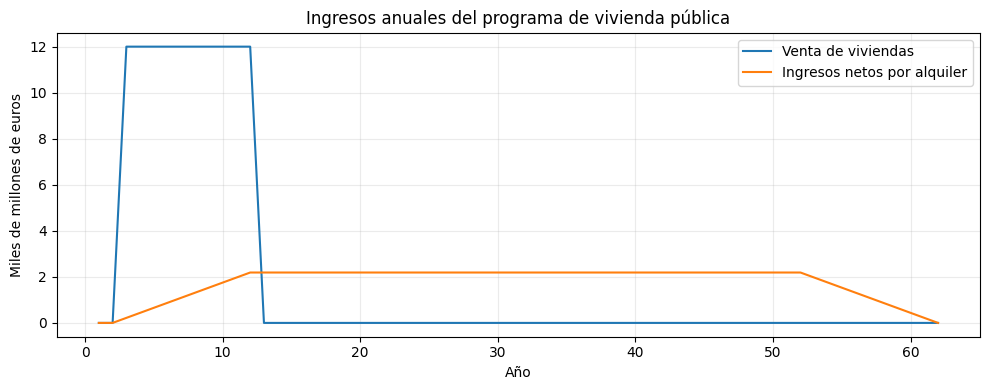

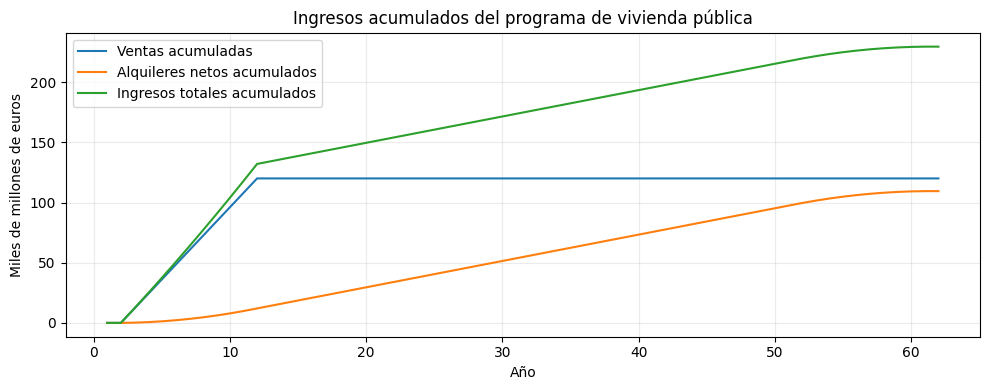

In [ ]:
# Annual programme receipts
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(receipts['Year'], receipts['Sales'] / 1e9, label='Venta de viviendas')
ax.plot(receipts['Year'], receipts['Net rent'] / 1e9, label='Ingresos netos por alquiler')

ax.set(
    xlabel='Año',
    ylabel='Miles de millones de euros',
    title='Ingresos anuales del programa de vivienda pública'
)

ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


# Cumulative programme receipts
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(receipts['Year'], receipts['Accumulated sales'] / 1e9, label='Ventas acumuladas')
ax.plot(receipts['Year'], receipts['Accumulated net rent'] / 1e9, label='Alquileres netos acumulados')
ax.plot(receipts['Year'], receipts['Accumulated receipts'] / 1e9, label='Ingresos totales acumulados')

ax.set(
    xlabel='Año',
    ylabel='Miles de millones de euros',
    title='Ingresos acumulados del programa de vivienda pública'
)

ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## **The Financing Model**

### 1. Financing decisions

For each repayment horizon, the model determines:

- **Primary bond issuance:** new debt raised to finance the programme
- **Refinancing:** new bonds issued to repay existing debt at maturity
- **Annual PGE contributions:** government transfers required to balance the programme's financing needs
- **Cash balances:** unrestricted liquidity remaining at the end of each year

All bonds pay fixed annual coupons and repay their principal at maturity. The model must satisfy annual cash-flow balances, liquidity requirements and prudential debt constraints.

### 2. Debt management constraints

The model imposes restrictions on the **entire outstanding bond portfolio**, including both primary and refinancing issuances.

These include limits on refinancing, minimum weighted average remaining maturity (WAM), and the proportion of debt maturing within the following three years.

The minimum WAM is adjusted as the repayment deadline approaches:

$WAM_t^{\min}=\min(8,H-t)$

where ($H$) is the selected repayment deadline and ($t$) is the current programme year.

Similarly, the three-year maturity concentration ceiling is relaxed during the final three years, when all remaining debt must mature before the deadline.

### 3. Lexicographic optimisation

The model uses **linear programming with three sequential objectives**, applied in order of priority:

1. **Minimise the maximum annual PGE contribution** to limit peak budgetary requirements
2. **Minimise cumulative PGE contributions** while preserving the first optimum within numerical tolerance
3. **Minimise total nominal interest payments** while preserving the preceding budget objectives

Each of the 33 repayment horizons is optimised independently, without imposing an external annual PGE ceiling.

The resulting solution identifies a feasible financing structure under the model's assumptions and constraints. It does not require the final unrestricted cash balance to be exactly zero.

In [ ]:
def build_bonds(deadline, rates, refinancing):
    """Bond alternatives and their annual incidence matrices."""

    # Bond structure: (issue type, issue year, maturity term, repayment year)
    # Primary issuance: new debt to finance housing construction.
    primary = [('Primary', y, m, y + m) for y in range(1, 12)
               for m in maturities if y + m <= deadline]

    # Refinancing: new debt issued to repay existing debt
    rollover = [('Refinancing', y, m, y + m) for y in range(2, deadline + 1)
                for m in maturities if y + m <= deadline] if refinancing else []

    bonds = primary + rollover
    count = len(bonds)

    # Rows represent programme years (row 0 is unused), columns represent bond alternatives
    issues = np.zeros((deadline + 1, count)) # year in which each bond is issued
    principal = np.zeros_like(issues) # year in which each bond's principal is repaid
    coupons = np.zeros_like(issues) # annual interest payment per euro issued
    debt = np.zeros_like(issues) # years in which each bond remains outstanding
    remaining_debt_years = np.zeros_like(issues) # years remaining until each bond matures

    # Fill each bond's column with its issuance, repayment, interest payments, outstanding debt, and remaining years to maturity.
    for j, (kind, year, tenor, maturity_year) in enumerate(bonds):
        issues[year, j] = 1
        principal[maturity_year, j] = 1
        coupons[year + 1:maturity_year + 1, j] = rates[tenor]
        debt[year:maturity_year, j] = 1
        remaining_debt_years[year:maturity_year, j] = (
            maturity_year - np.arange(year, maturity_year)
        )

    return bonds, issues, principal, coupons, debt, remaining_debt_years


def build_constraints(deadline, housing, bonds, issues, principal, coupons,
                      debt, remaining_debt_years, prudent, refinancing, treasury_limit):
    """Cash identities, reserve requirement, and prudential bond constraints."""

    scale = 1_000_000_000
    count = len(bonds)
    n = count + 2 * deadline + 1

    # Decision-vector layout: [bond issues | annual PGE | annual cash | PGE peak]
    def pge_col(year):
        return count + year - 1
    def cash_col(year):
        return count + deadline + year - 1

    annual_limit_col = n - 1

    # Store equality constraints and upper-bound inequality constraints
    equality_rows, equality_values = [], []
    upper_rows, upper_values = [], []
    refinancing_mask = np.array([kind == 'Refinancing' for kind, *_ in bonds])


    for year in range(1, deadline + 1):

        # Annual cash balance: C_t = C_(t-1) + F_t + E_t + P_t - I_t - A_t
        row = lil_matrix((1, n))
        row[0, :count] = principal[year] + coupons[year] - issues[year] # A_t + I_t - E_t
        row[0, pge_col(year)] = -1                                      # -P_t: annual government contribution
        row[0, cash_col(year)] = 1                                      # +C_t: ending cash balance

        if year > 1:
            row[0, cash_col(year - 1)] = -1                                     # -C_(t-1): previous year's ending cash
        equality_rows.append(row.tocsr())                                       # Store the cash-balance coefficients
        equality_values.append(housing.loc[year - 1, 'Operating cash'] / scale) # F_t: net housing cash flow

        # Each annual PGE contribution is bounded by the peak-PGE variable
        row = lil_matrix((1, n))
        row[0, pge_col(year)] = 1          # +P_t: government contribution in year t
        row[0, annual_limit_col] = -1      # -P_max: maximum annual contribution

        upper_rows.append(row.tocsr())
        upper_values.append(0)             # Right-hand side: P_t - P_max <= 0


        if refinancing:
            # New refinancing cannot exceed principal due in the same year (Refinancing constraint: R_t <= A_t)
            row = lil_matrix((1, n))
            row[0, :count] = issues[year] * refinancing_mask - principal[year]      # R_t - A_t
            upper_rows.append(row.tocsr())
            upper_values.append(0)           # Right-hand side: R_t - A_t <= 0


        if prudent:
            # Minimum weighted average remaining maturity: WAM_t >= min_wam
            min_wam = min(minimum_stable_wam, deadline - year)                  # 8 years, adjusted near repayment deadline
            row = lil_matrix((1, n))
            row[0, :count] = min_wam * debt[year] - remaining_debt_years[year]  # Minimum WAM constraint
            upper_rows.append(row.tocsr())
            upper_values.append(0)            # Right-hand side: minimum WAM condition <= 0

        if treasury_limit:
            # Limit the share of outstanding principal due within three years
            # The limit is relaxed once the repayment horizon is three years away
            remaining = deadline - year
            max_short_share = treasury_three_year_share if remaining > 3 else 1.0   # Treasury limit, relaxed in final 3 years
            short_debt = debt[year] * (remaining_debt_years[year] <= 3)             # Bonds maturing within 3 years

            row = lil_matrix((1, n))
            row[0, :count] = short_debt - max_short_share * debt[year]              # D_short_t - max_short_share * D_t
            upper_rows.append(row.tocsr())
            upper_values.append(0)          # Right-hand side: concentration constraint <= 0


    # Combine all annual constraints into matrices for the optimizer
    A_eq = vstack(equality_rows).tocsr()  # Coefficients of equality constraints
    b_eq = np.array(equality_values)      # Right-hand side of equality constraints

    A_ub = vstack(upper_rows).tocsr()     # Coefficients of inequality constraints
    b_ub = np.array(upper_values)         # Upper limits of inequality constraints

    # Decision variables are non-negative; cash must also meet the initial reserve.
    bounds = [(0, None)] * n              # Lower bound = 0, no explicit upper bound

    for year in range(1, 12):
        bounds[cash_col(year)] = (cash_reserve / scale, None)  # Minimum €3bn cash, years 1–11

    return A_eq, b_eq, A_ub, b_ub, bounds


def solve_financing(deadline, bonds, coupons, A_eq, b_eq, A_ub, b_ub, bounds,
                    objective_mode, annual_pge_ceiling):
    """Lexicographic PGE objectives or illustrative interest minimisation."""
    scale = 1_000_000_000
    count = len(bonds)
    n = count + 2 * deadline + 1
    annual_limit_col = n - 1

    # Solve a linear optimization problem, optionally adding new constraints
    def optimise(objective, more_rows=None, more_values=None):
        extra = more_rows if more_rows is not None else []  # Additional inequality rows
        limits = vstack([A_ub] + extra).tocsr() if extra else A_ub  # Combined constraint coefficients
        values = np.r_[b_ub, more_values] if more_values is not None else b_ub  # Combined upper bounds

        result = linprog(
            objective,         # Objective function to minimize
            A_ub=limits,       # Inequality coefficients
            b_ub=values,       # Inequality upper bounds
            A_eq=A_eq,         # Equality coefficients
            b_eq=b_eq,         # Equality right-hand sides
            bounds=bounds,     # Bounds on decision variables
            method='highs'     # HiGHS optimization solver
        )

        if not result.success:
            raise RuntimeError(result.message)  # Stop if optimization fails
        return result

    # Define the three optimization objectives.
    annual_objective = np.zeros(n)
    annual_objective[annual_limit_col] = 1  # Minimize maximum annual PGE contribution

    total_objective = np.zeros(n)
    total_objective[count:count + deadline] = 1  # Minimize cumulative PGE contributions

    interest_objective = np.zeros(n)
    interest_objective[:count] = coupons.sum(axis=0)  # Minimize total nominal interest payments

    # Convert optimization objectives into constraints to preserve previous results.
    ceiling_row = csr_matrix(annual_objective.reshape(1, -1))    # Maximum annual PGE
    total_row = csr_matrix(total_objective.reshape(1, -1))        # Cumulative PGE
    interest_row = csr_matrix(interest_objective.reshape(1, -1))  # Total nominal interest

    tolerance = 0.000001  # Allow €1,000 deviation from previous optimal values


    if objective_mode == 'lex':
        # Step 1: minimize the maximum annual government contribution.
        first = optimise(annual_objective)

        # Step 2: minimize cumulative PGE while preserving the optimal annual ceiling.
        second = optimise(
            total_objective,
            [ceiling_row],              # Constraint on maximum annual PGE
            [first.fun + tolerance])     # Optimal annual ceiling + €1,000 tolerance

        # Step 3: minimize interest while preserving both previous budget objectives.
        third = optimise(
            interest_objective,
            [ceiling_row, total_row],   # Constraints on annual and cumulative PGE
            [first.fun + tolerance, second.fun + tolerance])  # Previously optimized limits

    elif objective_mode == 'interest':
      # Sensitivity only: the PGE ceiling is a scenario, not an estimate of fiscal headroom.
        if annual_pge_ceiling is None:
            raise ValueError('The interest comparison needs a PGE scenario.')

        cap = annual_pge_ceiling / scale  # Convert annual PGE ceiling to billions

        # Step 1: minimize interest subject to the specified PGE ceiling.
        first = optimise(interest_objective, [ceiling_row], [cap])

        # Step 2: minimize cumulative PGE while preserving minimum interest.
        # Break ties by lower total PGE to avoid arbitrary unused public cash.
        third = optimise(total_objective,
                [ceiling_row, interest_row],  # Annual PGE and total interest constraints
                [cap, first.fun + tolerance])

    else:
        raise ValueError(f'Unknown objective_mode: {objective_mode}')
    return third.x


def summarise_solution(deadline, housing, bonds, values, principal,
                       coupons, debt, remaining_debt_years, return_issuances):
    """Convert optimisation variables into annual cash, debt, and bond tables."""
    scale = 1_000_000_000   # Convert billions into euros
    count = len(bonds)      # Number of possible bond issuances

    # Locate annual PGE and cash variables within the optimal decision vector
    def pge_col(year):
        return count + year - 1

    def cash_col(year):
        return count + deadline + year - 1

    rows = []
    issuance_rows = []

    # Extract bonds actually issued in the optimal solution
    for j, (kind, issue_year, tenor, due_year) in enumerate(bonds):
        amount = values[j] * scale    # Optimal bond amount in euros
        if amount > 20_000:           # Exclude negligible numerical amounts from the table
            issuance_rows.append({'Year': issue_year, 'Maturity': tenor,
                                  'Type': kind, 'Amount': amount, 'Due year': due_year})

    # Calculate annual bond issuance, refinancing, and outstanding debt
    for year in range(1, deadline + 1):
        # Primary issuance in euros
        primary_issued = sum(values[j] for j, bond in enumerate(bonds)
                             if bond[0] == 'Primary' and bond[1] == year) * scale
        # Refinancing issuance in euros
        refinanced = sum(values[j] for j, bond in enumerate(bonds)
                         if bond[0] == 'Refinancing' and bond[1] == year) * scale
        # Outstanding debt in billions
        outstanding = debt[year] @ values[:count]
        # Debt-weighted remaining years
        residual_years = remaining_debt_years[year] @ values[:count]
        # Store annual financial results from the optimal solution.
        rows.append({
            'Year': year,
            'Operating cash': housing.loc[year - 1, 'Operating cash'],   # Net housing cash flow
            'Primary issuance': primary_issued,                          # New primary financing
            'Refinancing': refinanced,                                   # New refinancing issuance
            'Interest': coupons[year] @ values[:count] * scale,          # Annual interest payments
            'Principal paid': principal[year] @ values[:count] * scale,  # Annual principal repayments
            'PGE': values[pge_col(year)] * scale,                        # Government contribution
            'Cash': values[cash_col(year)] * scale,                      # Year-end cash balance
            'Debt': outstanding * scale,                                 # Year-end outstanding debt
            'Residual maturity': (residual_years / outstanding           # Weighted average remaining maturity
                                  if outstanding > 1e-7 else np.nan)})

    flows = pd.DataFrame(rows)

    # Calculate beginning-of-year debt and the annual maturity share
    flows['Debt at start'] = flows['Debt'].shift(1).fillna(0)  # Outstanding debt at the end of the previous year

    flows['Maturing share'] = np.where(
        flows['Debt at start'] > 20_000,  # Avoid dividing by negligible amounts
        flows['Principal paid'] / flows['Debt at start'],  # Share of initial debt maturing during the year
        np.nan)  # Undefined when beginning-of-year debt is negligible


    # Calculate the maturity distribution of primary bond issuances
    mix = {}
    for tenor in maturities:
        amount = sum(values[j] for j, bond in enumerate(bonds)
                     if bond[0] == 'Primary' and bond[2] == tenor) * scale  # Total primary issuance by maturity
        if amount > 1_000:
            mix[tenor] = amount   # Exclude negligible issuance amounts

    primary_total = sum(mix.values())   # Total included primary issuance
    mix = {tenor: amount / primary_total for tenor, amount in mix.items()} if primary_total else {}  # Share of each maturity

    # Identify the final maturity year of bonds actually issued
    repayment_year = max((bond[3] for j, bond in enumerate(bonds)
                          if values[j] * scale > 20_000), default=0)    # Last bond repayment year

    # Summarize the main financial results of the optimal solution
    summary = {

        'Deadline': deadline,                                # Maximum allowed repayment horizon
        'PGE annual': flows['PGE'].max(),                    # Maximum annual government contribution
        'PGE total': flows['PGE'].sum(),                     # Cumulative government contributions
        'Interest total': flows['Interest'].sum(),           # Total nominal interest payments
        'Peak refinancing': flows['Refinancing'].max(),      # Maximum annual refinancing issuance
        'Peak principal due': flows['Principal paid'].max(), # Maximum annual principal repayment
        'Peak debt': flows['Debt'].max(),                    # Maximum year-end outstanding debt
        'Cash at deadline': flows['Cash'].iloc[-1],          # Cash balance at the repayment deadline
        'Actual repayment year': repayment_year,             # Final maturity of issued bonds
        'Primary mix': mix}                                  # Primary bond issuance shares by maturity

    # Create the detailed bond issuance table
    issuances = pd.DataFrame(issuance_rows, columns=['Year', 'Maturity', 'Type', 'Amount', 'Due year'])

    # Return annual flows and summary, optionally including individual bond issuances
    if return_issuances:
        return flows, summary, issuances
    return flows, summary


def financing_model(deadline, prudent=True, rent_share=rental_share,
                    price=sale_price, rate_change=0.0, extra_maintenance=0.0,
                    refinancing=True, return_issuances=False, treasury_limit=True,
                    objective_mode="lex", annual_pge_ceiling=None):
    """Execute the unchanged financial equations through four explicit steps."""

    # Step 1: calculate housing construction, sales, rental income, and operating cash flows
    housing = housing_schedule(deadline, rent_share, price, extra_maintenance)

    # Adjust the reference interest rates for the selected scenario
    rates = {m: reference_rates[m] + rate_change for m in maturities}
    if min(rates.values()) <= 0:
        raise ValueError('Interest rates must remain positive.')    # Reject non-positive interest rates

    # Step 2: construct available bonds and their financial incidence matrices
    bonds, issues, principal, coupons, debt, remaining = build_bonds(deadline, rates, refinancing)

    # Step 3: build cash-flow, refinancing, and prudential constraints
    A_eq, b_eq, A_ub, b_ub, bounds = build_constraints(
        deadline, housing, bonds, issues, principal, coupons, debt, remaining,
        prudent, refinancing, treasury_limit)

    # Step 4: solve the financing problem under the selected optimization objective
    values = solve_financing(deadline, bonds, coupons,
                             A_eq, b_eq, A_ub, b_ub, bounds,
                             objective_mode, annual_pge_ceiling)

    # Convert the optimal solution into annual financial results and summary statistics
    return summarise_solution(deadline, housing, bonds, values, principal, coupons, debt, remaining, return_issuances)

## **Q2. How does the PGE requirement vary by debt-repayment horizon?**

The programme's financing requirements depend on **how quickly the government repays the debt**. Shorter repayment horizons may require larger annual budget contributions, while longer horizons can spread these contributions over more years but potentially increase interest costs.

To examine this trade-off, the model independently optimises **33 repayment horizons, from 30 to 62 years**, without imposing an external annual PGE ceiling.

For each horizon, we compare three key outcomes:

- **Peak annual PGE:** the maximum contribution required from the government in any single year
- **Cumulative PGE:** the total government contributions over the repayment period
- **Total interest:** the nominal coupon payments associated with the financing strategy

The **50-year repayment horizon** serves as the central reporting benchmark. It is an illustrative reference, not an assumed optimal solution or a requirement arising from the 50-year rental-income period of each housing cohort.

By comparing all horizons, we identify the trade-offs between annual budgetary pressure and financing costs, including strategies that are **Pareto-dominated** by alternatives requiring both lower peak PGE contributions and lower interest payments.

These results describe financing requirements under the model's assumptions. They do not, by themselves, establish whether the estimated contributions would be affordable within Spain's public finances.

In [ ]:
reference_deadline = 50
results = []
solutions = {}
portfolio_checks = []

# Solve the financing model for all repayment horizons from 30 to 62 years
for deadline in range(30, 63):
    flows, summary, issued = financing_model(deadline, return_issuances=True)
    results.append(summary)
    solutions[deadline] = flows

    if deadline == reference_deadline:
        reference_issuances = issued    # Bond portfolio for the 50-year scenario

    # Reconstruct prudential indicators from material bond issuances
    # Issues below €20,000 are excluded from the exported issuance table
    for year in range(1, deadline):
        outstanding = issued[(issued['Year'] <= year) & (issued['Due year'] > year)]
        total = outstanding['Amount'].sum()     # Total outstanding principal

        if total < 1_000_000:
            continue          # Skip portfolios with negligible outstanding debt

        residual = outstanding['Due year'] - year    # Remaining years until maturity
        wam = (outstanding['Amount'] * residual).sum() / total    # Weighted average maturity
        short_share = outstanding.loc[residual <= 3, 'Amount'].sum() / total    # Debt due within 3 years

        wam_floor = min(minimum_stable_wam, deadline - year)    # Required minimum WAM
        short_ceiling = treasury_three_year_share if deadline - year > 3 else 1.0   # Maximum short-term share

        assert wam >= wam_floor - 1e-5, (deadline, year, 'WAM')
        assert short_share <= short_ceiling + 1e-5, (deadline, year, '3-year share')

        portfolio_checks.append((deadline, year, wam, short_share))

print(f'Prudential restrictions verified for all {len(results)} repayment horizons '
      f'and {len(portfolio_checks)} non-trivial annual portfolios.')

# Compare annual PGE, cumulative PGE, and interest across repayment horizons
comparison = pd.DataFrame(results)
comparison['Annual saving from another year'] = -comparison['PGE annual'].diff()    # Change in peak PGE from extending the horizon
comparison['Additional interest'] = comparison['Interest total'].diff()             # Change in total nominal interest

# The 50-year benchmark is not selected using an exogenous annual PGE cap
budget_tolerance = 1_000  # Numerical comparison tolerance in euros
reference_row = comparison.loc[comparison['Deadline'] == reference_deadline].iloc[0]

# Identify horizons dominated on peak annual PGE and total nominal interest
# A horizon is Pareto-dominated when another has no greater peak annual PGE and no greater total interest, and at least one of the two is strictly lower.
dominated = []
for _, candidate in comparison.iterrows():
    other = comparison.loc[comparison['Deadline'] != candidate['Deadline']]

    # Another horizon is no worse in either objective (within tolerance)
    weak = ((other['PGE annual'] <= candidate['PGE annual'] + budget_tolerance) &
            (other['Interest total'] <= candidate['Interest total'] + budget_tolerance))

    # At least one objective must be strictly better beyond tolerance
    strict = ((other['PGE annual'] < candidate['PGE annual'] - budget_tolerance) |
              (other['Interest total'] < candidate['Interest total'] - budget_tolerance))

    dominated.append(bool((weak & strict).any()))
comparison['Pareto dominated'] = dominated


# Display the main results of the reference financing scenario
print('PGE cap: none (annual PGE is an endogenous output)')
print(f'Reference debt deadline: year {reference_deadline}')
print(f'Peak annual PGE at reference: {euros(reference_row["PGE annual"])}')
print(f'Total nominal interest at reference: {euros(reference_row["Interest total"])}')
print(f'Cumulative PGE transfers at reference: {euros(reference_row["PGE total"])}')
print(f'Pareto-dominated horizon solutions: {int(comparison["Pareto dominated"].sum())}')

# Select representative horizons for the financing trade-off table
tradeoff = comparison.loc[comparison['Deadline'].isin([30, 35, 40, 45, 49, 50, 51, 55, 60, 62]),
    ['Deadline', 'PGE annual', 'PGE total', 'Interest total', 'Pareto dominated']].copy()

for column in ['PGE annual', 'PGE total', 'Interest total']:
    tradeoff[column] = tradeoff[column].map(euros)

print('Uncapped financing horizon comparison:')
display(tradeoff)


# The selected reference scenario: investment, interest and public financing.
# Retrieve annual financial flows for the 50-year reference scenario
reference_flows = solutions[reference_deadline]

# Combine financing results with housing costs and rental allocations
reference_costs = reference_flows.merge(housing[['Year', 'Construction', 'Sales', 'Net rent',
        'Management allocation', 'Maintenance allocation', 'Restricted allocation']], on='Year')

# Calculate cumulative investment, financing costs, and public contributions
reference_costs['Cumulative investment'] = reference_costs['Construction'].cumsum()
reference_costs['Cumulative interest'] = reference_costs['Interest'].cumsum()
reference_costs['Cumulative PGE'] = reference_costs['PGE'].cumsum()
reference_costs['Cumulative management allocation'] = reference_costs['Management allocation'].cumsum()
reference_costs['Cumulative maintenance allocation'] = reference_costs['Maintenance allocation'].cumsum()

# Combine cumulative construction, interest, and allocated rental operating costs
reference_costs['Cumulative planned costs and allocations'] = (reference_costs['Cumulative investment'] +
    reference_costs['Cumulative interest'] + reference_costs['Cumulative management allocation'] +
    reference_costs['Cumulative maintenance allocation'])

Prudential restrictions verified for all 33 repayment horizons and 1485 non-trivial annual portfolios.
PGE cap: none (annual PGE is an endogenous output)
Reference debt deadline: year 50
Peak annual PGE at reference: 953.986.394 €
Total nominal interest at reference: 82.911.961.787 €
Cumulative PGE transfers at reference: 47.699.161.787 €
Pareto-dominated horizon solutions: 1
Uncapped financing horizon comparison:


    Deadline       PGE annual         PGE total    Interest total  \
0         30  2.170.975.475 €  65.129.224.576 €  56.566.024.576 €   
5         35  1.457.133.949 €  50.999.616.537 €  53.380.416.537 €   
10        40  1.235.652.518 €  49.426.003.818 €  62.750.803.818 €   
15        45  1.073.181.781 €  48.293.056.348 €  72.561.856.348 €   
19        49    972.493.888 €  47.652.050.887 €  80.676.050.887 €   
20        50    953.986.394 €  47.699.161.787 €  82.911.961.787 €   
21        51    932.064.994 €  47.535.152.371 €  84.936.752.371 €   
25        55    864.183.731 €  47.529.908.039 €  92.373.428.039 €   
30        60    818.518.514 €  49.110.892.860 €  98.332.012.860 €   
32        62    810.094.164 €  50.225.632.770 €  99.665.632.770 €   

    Pareto dominated  
0               True  
5              False  
10             False  
15             False  
19             False  
20             False  
21             False  
25             False  
30             False  
32        

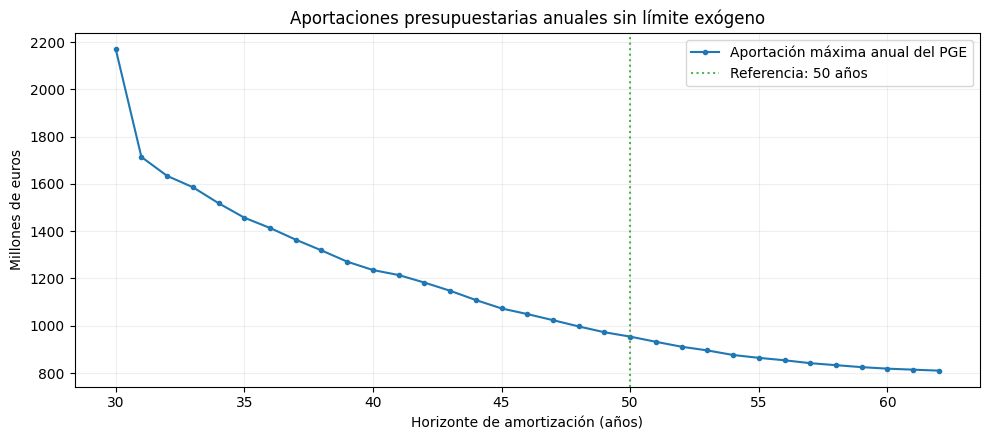

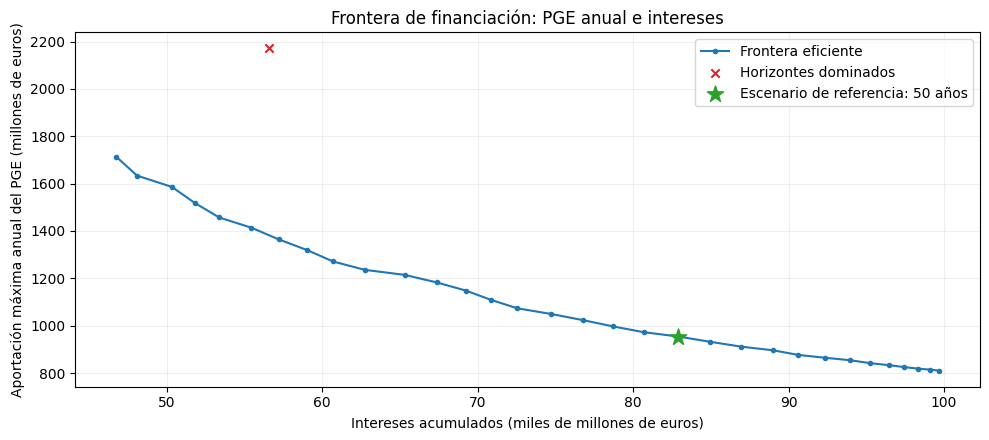

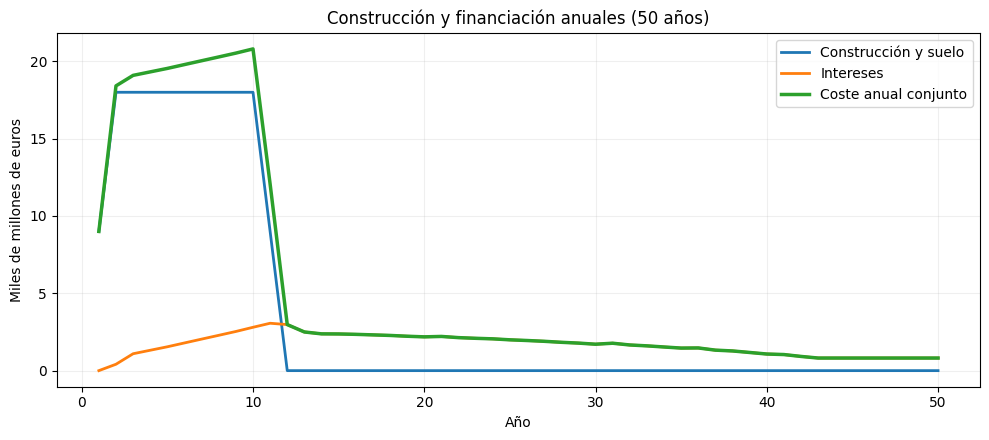

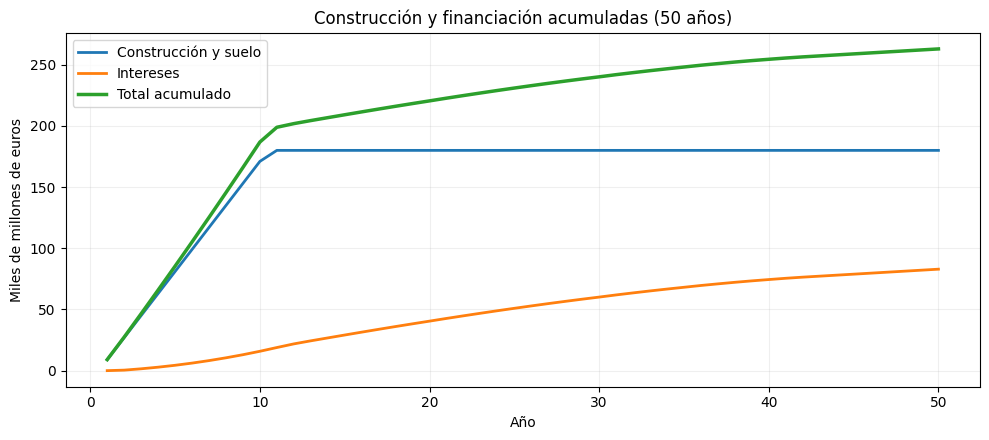

In [ ]:
# Plot the minimum annual peak PGE required for each repayment horizon
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(comparison['Deadline'], comparison['PGE annual'] / 1e6,
        marker='o', markersize=3, label='Aportación máxima anual del PGE')

# Highlight the 50-year reference horizon
ax.axvline(reference_deadline, linestyle=':', color='tab:green', alpha=0.8,
           label=f'Referencia: {reference_deadline} años')

ax.set(xlabel='Horizonte de amortización (años)', ylabel='Millones de euros',
       title='Aportaciones presupuestarias anuales sin límite exógeno')
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()



# Plot the trade-off between maximum annual PGE and total nominal interest
fig, ax = plt.subplots(figsize=(10, 4.5))

# Select non-dominated financing horizons
frontier = comparison.loc[~comparison['Pareto dominated']].sort_values('Interest total')
ax.plot(frontier['Interest total'] / 1e9, frontier['PGE annual'] / 1e6,
        marker='o', markersize=3, label='Frontera eficiente')

# Show dominated horizons separately
dominated_rows = comparison.loc[comparison['Pareto dominated']]
if not dominated_rows.empty:
    ax.scatter(dominated_rows['Interest total'] / 1e9,
               dominated_rows['PGE annual'] / 1e6,
               marker='x', color='tab:red', label='Horizontes dominados')

# Highlight the reference financing scenario
ax.scatter([reference_row['Interest total'] / 1e9],
           [reference_row['PGE annual'] / 1e6], marker='*', s=150, zorder=5,
           color='tab:green', label=f'Escenario de referencia: {reference_deadline} años')

ax.set(xlabel='Intereses acumulados (miles de millones de euros)',
       ylabel='Aportación máxima anual del PGE (millones de euros)',
       title='Frontera de financiación: PGE anual e intereses')
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()



# Calculate annual construction and interest costs, excluding reserved rental allocations
reference_costs['Construction and financing'] = (
    reference_costs['Construction'] + reference_costs['Interest'])
reference_costs['Cumulative construction and financing'] = (
    reference_costs['Cumulative investment'] + reference_costs['Cumulative interest'])

# Plot annual construction expenditure, interest payments, and their sum
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(reference_costs['Year'], reference_costs['Construction'] / 1e9,
        label='Construcción y suelo', linewidth=2)
ax.plot(reference_costs['Year'], reference_costs['Interest'] / 1e9,
        label='Intereses', linewidth=2)
ax.plot(reference_costs['Year'], reference_costs['Construction and financing'] / 1e9,
        label='Coste anual conjunto', linewidth=2.5)

ax.set(xlabel='Año', ylabel='Miles de millones de euros',
       title=f'Construcción y financiación anuales ({reference_deadline} años)')
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()



# Plot cumulative construction costs, nominal interest, and their combined total
# Restricted rental management and maintenance allocations are excluded
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(reference_costs['Year'], reference_costs['Cumulative investment'] / 1e9,
        label='Construcción y suelo', linewidth=2)
ax.plot(reference_costs['Year'], reference_costs['Cumulative interest'] / 1e9,
        label='Intereses', linewidth=2)
ax.plot(reference_costs['Year'], reference_costs['Cumulative construction and financing'] / 1e9,
        label='Total acumulado', linewidth=2.5)

ax.set(xlabel='Año', ylabel='Miles de millones de euros',
       title=f'Construcción y financiación acumuladas ({reference_deadline} años)')
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


## **Q2b. What is the interest cost of smoothing annual PGE contributions?**

Reducing the maximum annual contribution from the Spanish State Budget (PGE) can help distribute the programme's financing requirements more evenly over time. However, this may require greater reliance on public debt, potentially increasing total interest payments.

To quantify this trade-off, we **hold the 50-year repayment horizon fixed** and compare two financing approaches:

1. **Baseline optimisation:** minimises peak annual PGE, followed by cumulative PGE and nominal interest payments.
2. **Interest-minimising scenarios:** allow different maximum annual PGE contributions and minimise nominal interest first, followed by cumulative PGE.

Both approaches use the **same housing assumptions, financing constraints and prudential debt rules**.

This comparison shows how much nominal interest could be saved by allowing higher annual public contributions, and therefore the potential financing cost of smoothing budgetary requirements.

Importantly, **higher PGE contributions are not costless**: they represent additional public resources allocated to the programme. Consequently, lower interest payments do not necessarily imply a better overall economic outcome or demonstrate fiscal affordability.

                          Strategy  Annual PGE scenario (M€)  Peak PGE (M€)  \
0      Baseline: minimise PGE peak                    953.99         953.99   
1  Minimise interest, PGE scenario                   1000.00        1000.00   
2  Minimise interest, PGE scenario                   1250.00        1250.00   
3  Minimise interest, PGE scenario                   1500.00        1500.00   
4  Minimise interest, PGE scenario                   2000.00        2000.00   
5  Minimise interest, PGE scenario                   3000.00        3000.00   
6  Minimise interest, PGE scenario                   5000.00        5000.00   

   Total PGE (M€)  Bond interest (M€)  Interest saved vs baseline (M€)  
0        47699.16            82911.96                             0.00  
1        43304.26            78517.06                          4394.90  
2        40718.37            62365.01                         20546.95  
3        41360.41            52408.63                         30503.33  
4 

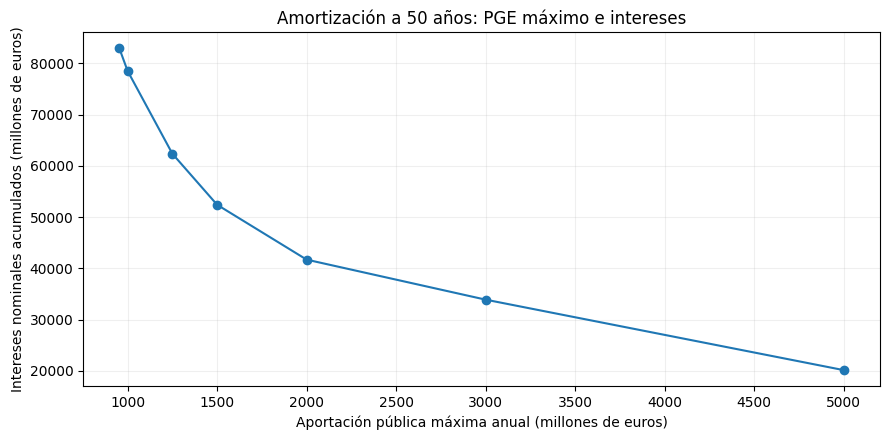

In [ ]:
# Sensitivity analysis: compare PGE-peak minimisation with interest minimisation
frontier_rows = []
base_peak = float(reference_row['PGE annual'])  # Baseline maximum annual PGE in euros

# Store the baseline solution for comparison
frontier_rows.append({'Strategy': 'Baseline: minimise PGE peak',
                     'Annual PGE scenario (M€)': round(base_peak / 1e6, 2),
                     'Peak PGE (M€)': reference_row['PGE annual'] / 1e6,
                     'Total PGE (M€)': reference_row['PGE total'] / 1e6,
                     'Bond interest (M€)': reference_row['Interest total'] / 1e6})

# Re-optimise the 50-year scenario with different illustrative annual PGE ceilings
for cap_millions in [1000, 1250, 1500, 2000, 3000, 5000]:
    _, scenario = financing_model(reference_deadline,
                                  objective_mode='interest',
                                  annual_pge_ceiling=cap_millions * 1e6)

    frontier_rows.append({'Strategy': 'Minimise interest, PGE scenario',
                         'Annual PGE scenario (M€)': cap_millions,
                         'Peak PGE (M€)': scenario['PGE annual'] / 1e6,
                         'Total PGE (M€)': scenario['PGE total'] / 1e6,
                         'Bond interest (M€)': scenario['Interest total'] / 1e6})

# Compare interest costs and savings relative to the baseline
interest_frontier = pd.DataFrame(frontier_rows)
interest_frontier['Interest saved vs baseline (M€)'] = (
    reference_row['Interest total'] / 1e6 - interest_frontier['Bond interest (M€)'])

display(interest_frontier.round(2))

# Plot the trade-off between actual peak annual PGE and total nominal interest
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(interest_frontier['Peak PGE (M€)'],
        interest_frontier['Bond interest (M€)'], marker='o')

ax.set(xlabel='Aportación pública máxima anual (millones de euros)',
       ylabel='Intereses nominales acumulados (millones de euros)',
       title='Amortización a 50 años: PGE máximo e intereses')
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Verify that interest minimisation does not worsen baseline interest costs
assert (interest_frontier['Interest saved vs baseline (M€)'] >= -0.01).all()

## **Annual Bond Issuance and Refinancing**

The following tables and charts illustrate how the programme finances its obligations through bond issuance over time, distinguishing between two types of debt operations:

- **Primary issuance:** new borrowing used to finance the programme's funding needs.
- **Refinancing:** new bonds issued to repay existing bonds when they mature, without increasing outstanding debt by itself.

Both types of issuance are presented by year and original bond maturity (3, 5, 10, 15, 20 and 30 years), allowing us to examine how the financing strategy and maturity composition evolve over time.

**Refinancing is a financing flow, not an additional economic cost.** Its financial consequences arise through the interest payments associated with the newly issued bonds.

In [ ]:
# Reuse bond issuances from the previously computed 50-year reference scenario
bond_issues = reference_issuances.copy()

# Generate separate tables for primary issuance and refinancing
for issue_type, heading in [('Primary', 'Initial bond issues (years 1–11)'),
                            ('Refinancing', 'Refinancing by year and maturity')]:

    subset = bond_issues[bond_issues['Type'] == issue_type]  # Select bonds by issuance type

    # Group bond amounts by issuance year and maturity
    annual_issues = subset.pivot_table(index='Year', columns='Maturity', values='Amount',
                                      aggfunc='sum', fill_value=0)

    annual_issues = annual_issues.reindex(columns=maturities, fill_value=0)  # Include all available maturities

    if issue_type == 'Primary':
        annual_issues = annual_issues.reindex(range(1, 12), fill_value=0)  # Include all primary issuance years

    annual_issues['Total'] = annual_issues.sum(axis=1)  # Total bond issuance per year

    print(heading)
    display(annual_issues.map(euros))  # Display amounts formatted in euros

    # Store the resulting tables for subsequent analysis
    if issue_type == 'Primary':
        primary_issues = annual_issues.copy()
    else:
        refinancing_issues = annual_issues.copy()

Initial bond issues (years 1–11)


Maturity                3                5               10   15  \
Year                                                               
1         2.203.721.228 €  5.198.767.919 €  1.045.570.635 €  0 €   
2         2.269.655.200 €  3.868.834.042 €  8.294.409.215 €  0 €   
3                     0 €  3.936.358.508 €              0 €  0 €   
4                     0 €  4.670.081.522 €              0 €  0 €   
5                     0 €  1.739.849.832 €  3.467.789.352 €  0 €   
6                     0 €              0 €  5.629.180.489 €  0 €   
7                     0 €  4.060.545.041 €  1.929.620.954 €  0 €   
8                     0 €    496.096.268 €  5.520.740.342 €  0 €   
9                     0 €  4.083.434.988 €              0 €  0 €   
10                    0 €              0 €  4.456.322.265 €  0 €   
11                    0 €              0 €  1.561.622.570 €  0 €   

Maturity               20               30             Total  
Year                                                

Refinancing by year and maturity


Maturity                3                5               10               15  \
Year                                                                           
4                     0 €  2.203.721.228 €              0 €              0 €   
5                     0 €              0 €  2.269.655.200 €              0 €   
6                     0 €  4.610.851.054 €              0 €              0 €   
7                     0 €              0 €  2.708.497.729 €              0 €   
8                     0 €  2.957.038.227 €              0 €              0 €   
9                     0 €    769.546.440 €  3.614.026.699 €              0 €   
10                    0 €              0 €  1.739.849.832 €              0 €   
11                    0 €              0 €              0 €              0 €   
14                    0 €              0 €  4.088.240.440 €              0 €   
15                    0 €              0 €  3.072.652.849 €              0 €   
16                    0 €  1.117.754.292

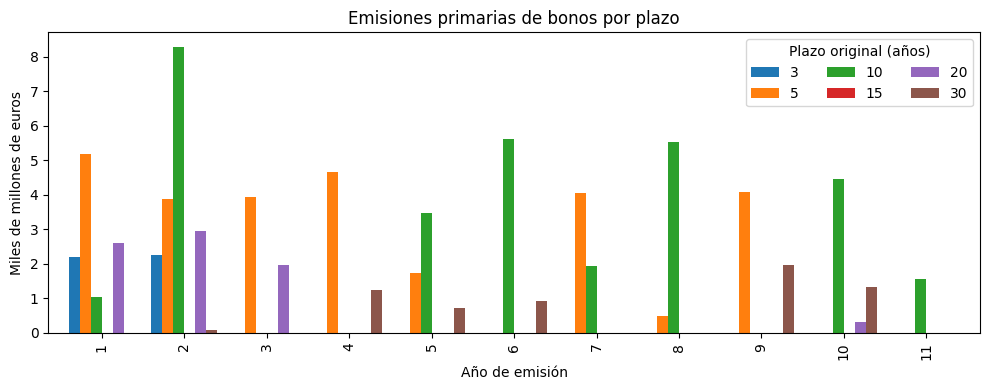

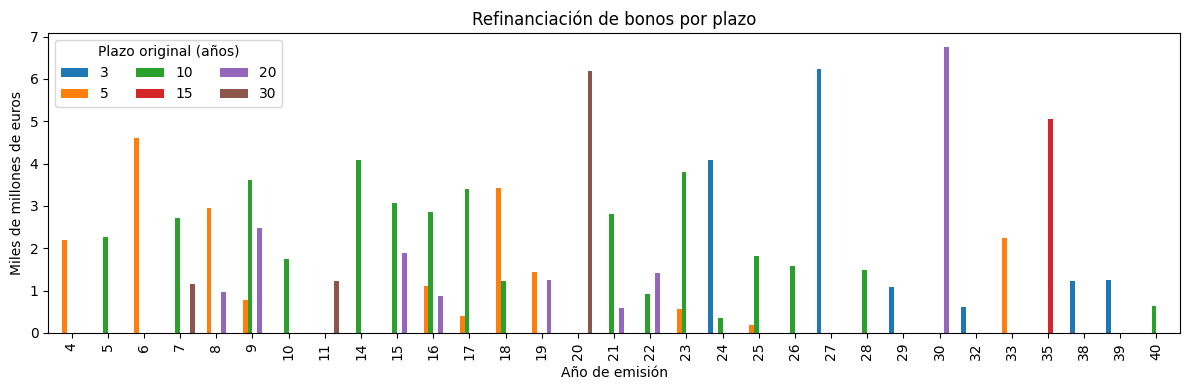

In [ ]:
# Plot primary bond issuance by year and original maturity
fig, ax = plt.subplots(figsize=(10, 4))
primary_issues[maturities].div(1e9).plot(kind='bar', stacked=False, ax=ax, width=0.8)

ax.set(xlabel='Año de emisión', ylabel='Miles de millones de euros',
       title='Emisiones primarias de bonos por plazo')
ax.legend(title='Plazo original (años)', ncol=3)
plt.tight_layout()
plt.show()

# Plot refinancing bond issuance by year and original maturity
fig, ax = plt.subplots(figsize=(12, 4))
refinancing_issues[maturities].div(1e9).plot(kind='bar', stacked=False, ax=ax, width=0.8)

ax.set(xlabel='Año de emisión',
       ylabel='Miles de millones de euros',
       title='Refinanciación de bonos por plazo')
ax.legend(title='Plazo original (años)', ncol=3)
plt.tight_layout()
plt.show()

# Verify that bond issuance tables match the annual cash-flow ledger
assert abs(primary_issues['Total'].sum() - reference_flows['Primary issuance'].sum()) < 30_000  # Primary issuance reconciliation
assert abs(refinancing_issues['Total'].sum() - reference_flows['Refinancing'].sum()) < 30_000  # Refinancing reconciliation

## **Q3. How is the outstanding debt distributed?**

The composition of outstanding public debt matters because it determines **when the programme must repay its bonds and how exposed it is to refinancing risk**.

The following chart shows how the outstanding debt portfolio evolves over time, distinguishing bonds according to their **original issuance maturity** (3, 5, 10, 15, 20 and 30 years).

The 100% stacked-area chart represents the proportion of outstanding principal associated with each original maturity. Each year's shares add up to 100%, allowing us to observe changes in the portfolio's composition independently of its total size.

Importantly, **original maturity and remaining maturity are different concepts**. For example, a 30-year bond with only two years left before repayment still belongs to the 30-year category in this chart, but contributes to the share of debt maturing within the next three years.

The model therefore evaluates refinancing risk separately through two prudential indicators:

- **Weighted average remaining maturity (WAM):** the average time until outstanding principal must be repaid, weighted by its amount
- **Three-year maturity concentration:** the proportion of outstanding principal scheduled to mature within the next three years

Both indicators are calculated using the **entire outstanding debt portfolio**, including bonds issued for refinancing.

In [ ]:
# Calculate annual outstanding debt and three-year maturity concentration
risk_rows = []

for year in range(1, reference_deadline + 1):
    # Select bonds issued and still outstanding at the end of each year
    remaining = bond_issues[(bond_issues['Year'] <= year) &
                            (bond_issues['Due year'] > year)]

    debt_outstanding = remaining['Amount'].sum()  # Total outstanding principal
    due_three = remaining.loc[remaining['Due year'] <= year + 3, 'Amount'].sum()  # Principal due within 3 years

    # Store annual refinancing risk indicators
    risk_rows.append({'Year': year, 'Debt outstanding': debt_outstanding,
                      'Due within 3 years': due_three,
                      'Three-year maturity share': due_three / debt_outstanding
                      if debt_outstanding > 20_000 else np.nan})

refinancing_risk = pd.DataFrame(risk_rows)  # Annual refinancing risk table

# Display selected years of the 50-year reference scenario
print('Maturity concentration and debt stock (selected years):')
risk_display = refinancing_risk[refinancing_risk['Year'].isin(
    [1, 3, 5, 10, 15, 20, 25, 30, 35, reference_deadline])].copy()

# Format monetary amounts and maturity shares for presentation
for field in ['Debt outstanding', 'Due within 3 years']:
    risk_display[field] = risk_display[field].map(euros)

risk_display['Three-year maturity share'] = risk_display['Three-year maturity share'].map(
    lambda v: '—' if pd.isna(v) else f'{v:.1%}')

display(risk_display)

Maturity concentration and debt stock (selected years):


    Year  Debt outstanding Due within 3 years Three-year maturity share
0      1  11.046.013.606 €    2.203.721.228 €                     20.0%
2      3  34.425.163.921 €    9.672.144.347 €                     28.1%
4      5  46.283.787.202 €   13.003.960.469 €                     28.1%
9     10  76.396.635.929 €   21.464.510.439 €                     28.1%
14    15  56.192.900.843 €   15.788.039.513 €                     28.1%
19    20  52.781.249.298 €   14.043.279.694 €                     26.6%
24    25  46.674.914.759 €   13.113.852.239 €                     28.1%
29    30  41.480.326.024 €    8.694.623.101 €                     21.0%
34    35  34.038.252.874 €    8.270.314.917 €                     24.3%
49    50               0 €                0 €                         —

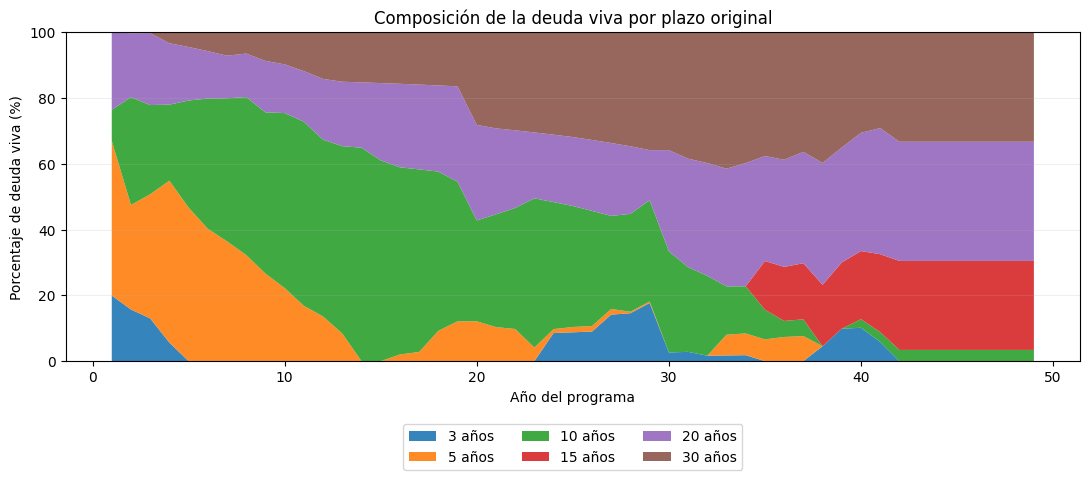

In [ ]:
# Calculate annual shares of outstanding debt by original bond maturity
# Shares sum to 100% whenever outstanding debt exceeds €20,000
stock_rows = []

for year in range(1, reference_deadline + 1):
    # Select bonds still outstanding at the end of each year
    outstanding = bond_issues[(bond_issues['Year'] <= year) & (bond_issues['Due year'] > year)]

    # Aggregate outstanding principal by original bond maturity
    amounts = outstanding.groupby('Maturity')['Amount'].sum().reindex(maturities, fill_value=0)
    total = amounts.sum()  # Total outstanding principal

    if total > 20_000:
        stock_rows.append({'Year': year, **{m: 100 * amounts[m] / total for m in maturities}})  # Percentage by maturity

bond_weights = pd.DataFrame(stock_rows)  # Annual debt composition table

# Plot the evolution of outstanding debt composition by original maturity
fig, ax = plt.subplots(figsize=(11, 5))
ax.stackplot(bond_weights['Year'], *[bond_weights[m] for m in maturities],
             labels=[f'{m} años' for m in maturities], alpha=0.90)

ax.set(xlabel='Año del programa',
       ylabel='Porcentaje de deuda viva (%)',
       title='Composición de la deuda viva por plazo original',
       ylim=(0, 100))
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.17))
ax.grid(axis='y', alpha=0.2)
plt.tight_layout()
plt.show()

### **Treasury Benchmark: Debt Maturity and Refinancing Risk**

To assess the programme's debt management strategy, we compare its maturity profile with that of the **Spanish Treasury**, using 66 outstanding government bonds and obligations as of 31 October 2026, excluding Treasury bills.

The comparison focuses on two indicators:

- **Weighted average remaining maturity (WAM):** how many years, on average, remain until outstanding debt must be repaid
- **Three-year maturity concentration:** the percentage of outstanding principal scheduled to mature within the next three years

These indicators help evaluate whether the programme maintains a debt maturity structure broadly consistent with the reference portfolio.

However, the comparison has an important limitation: **the Spanish Treasury manages an ongoing public debt portfolio, whereas the housing programme is designed to repay its entire debt by a fixed deadline**.

As the programme approaches that deadline, its remaining debt necessarily becomes shorter-term. The model therefore gradually reduces the minimum WAM requirement and removes the three-year maturity concentration ceiling during the final three years.

These adjustments are **intentional features of the financing model**.

In [ ]:
# Compare programme debt maturity indicators with the official Spanish Treasury benchmark
# Include primary and refinancing bonds while their principal remains outstanding
comparison_rows = []

for year in range(1, reference_deadline + 1):
    # Select bonds outstanding at the end of each year
    outstanding = bond_issues[(bond_issues['Year'] <= year) & (bond_issues['Due year'] > year)]
    stock = outstanding['Amount'].sum()  # Total outstanding programme debt

    # Calculate the weighted average remaining maturity
    wam = ((outstanding['Due year'] - year) * outstanding['Amount']).sum() / stock if stock > 20_000 else np.nan

    # Calculate principal due within the next three years
    near = outstanding.loc[outstanding['Due year'] <= year + 3, 'Amount'].sum()

    comparison_rows.append({
        'Year': year,
        'Programme outstanding (€)': stock,
        'Programme WAM (years)': wam,
        'Programme due within 3 years (%)': 100 * near / stock if stock > 1_000_000 else np.nan,
        'Treasury WAM (years)': treasury_wam,  # Official Treasury residual maturity benchmark
        'Treasury due within 3 years (%)': 100 * treasury_three_year_share  # Official short-term debt share
    })

treasury_comparison = pd.DataFrame(comparison_rows)  # Annual programme and Treasury comparison

# Calculate the minimum WAM required for each programme year
treasury_comparison['Minimum required WAM (years)'] = [
    min(minimum_stable_wam, reference_deadline - year)
    for year in treasury_comparison['Year']
]

# Relax the short-term maturity concentration ceiling during the final three years
treasury_comparison['Maximum permitted 3-year share (%)'] = [
    100 * (treasury_three_year_share if reference_deadline - y > 3 else 1.0)
    for y in treasury_comparison['Year']
]

# Display the Spanish Treasury benchmark
print('Spanish Treasury benchmark (31 October 2026):')
display(pd.DataFrame([{
    'Treasury bond stock': euros(treasury_total * 1_000_000),
    'Weighted residual maturity': f'{treasury_wam:.2f} years',
    'Due within 3 years': f'{treasury_three_year_share:.2%}'
}]))

# Select representative years for the comparison table
print('Annual comparison, selected years:')
selected_years = sorted(set([1, 3, 5, 10, 15, 20, 25, reference_deadline - 10,
                             reference_deadline - 5, reference_deadline]))

selected = treasury_comparison[treasury_comparison['Year'].isin(selected_years)].copy()
selected['Programme outstanding (€)'] = selected['Programme outstanding (€)'].map(euros)

# Format maturity indicators and percentages for presentation
for col in ['Programme WAM (years)', 'Treasury WAM (years)']:
    selected[col] = selected[col].map(lambda v: '—' if pd.isna(v) else f'{v:.2f}')

for col in ['Programme due within 3 years (%)', 'Treasury due within 3 years (%)',
            'Maximum permitted 3-year share (%)']:
    selected[col] = selected[col].map(lambda v: '—' if pd.isna(v) else f'{v:.2f}%')

display(selected)

Spanish Treasury benchmark (31 October 2026):


   Treasury bond stock Weighted residual maturity Due within 3 years
0  1.437.965.900.000 €                 8.18 years             28.10%

Annual comparison, selected years:


    Year Programme outstanding (€) Programme WAM (years)  \
0      1          11.046.013.606 €                  8.60   
2      3          34.425.163.921 €                  8.28   
4      5          46.283.787.202 €                  8.00   
9     10          76.396.635.929 €                  8.60   
14    15          56.192.900.843 €                  8.77   
19    20          52.781.249.298 €                 10.52   
24    25          46.674.914.759 €                  9.82   
39    40          24.327.809.781 €                  8.00   
44    45          18.625.979.363 €                  5.00   
49    50                       0 €                     —   

   Programme due within 3 years (%) Treasury WAM (years)  \
0                            19.95%                 8.18   
2                            28.10%                 8.18   
4                            28.10%                 8.18   
9                            28.10%                 8.18   
14                           28.10%    

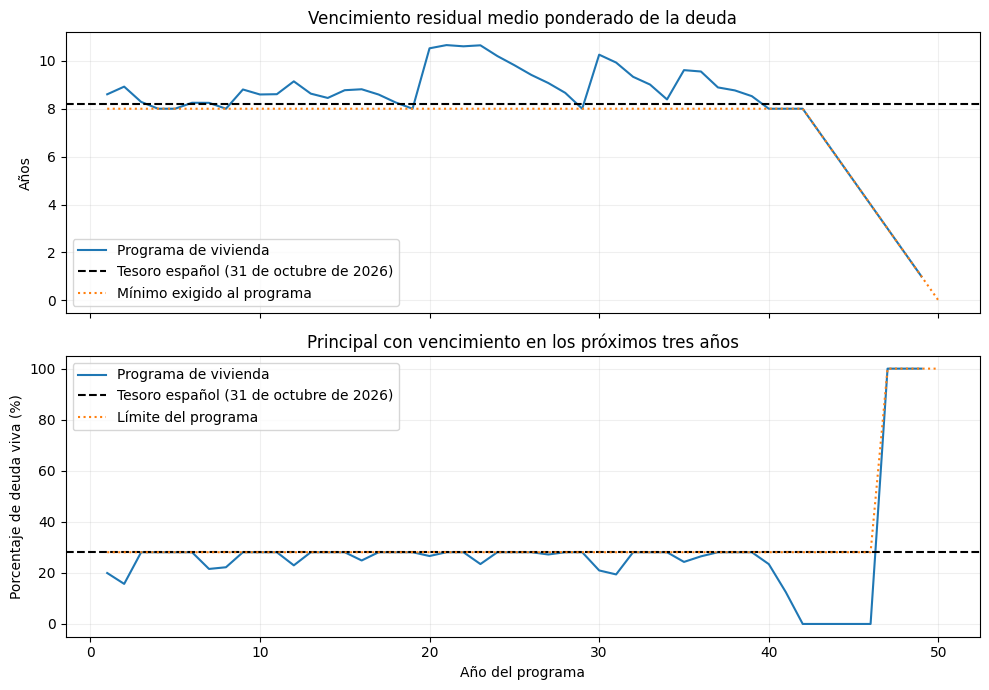

In [ ]:
# Compare programme debt maturity indicators with the Spanish Treasury benchmark
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

# Plot weighted average remaining maturity (WAM)
axes[0].plot(treasury_comparison['Year'], treasury_comparison['Programme WAM (years)'],
             label='Programa de vivienda')
axes[0].axhline(treasury_wam, color='black', linestyle='--',
                label='Tesoro español (31 de octubre de 2026)')
axes[0].plot(treasury_comparison['Year'], treasury_comparison['Minimum required WAM (years)'],
             linestyle=':', label='Mínimo exigido al programa')

axes[0].set_ylabel('Años')
axes[0].set_title('Vencimiento residual medio ponderado de la deuda')
axes[0].legend()
axes[0].grid(alpha=.2)

# Plot the share of outstanding debt maturing within three years
axes[1].plot(treasury_comparison['Year'], treasury_comparison['Programme due within 3 years (%)'],
             label='Programa de vivienda')
axes[1].axhline(100 * treasury_three_year_share, color='black', linestyle='--',
                label='Tesoro español (31 de octubre de 2026)')
axes[1].plot(treasury_comparison['Year'], treasury_comparison['Maximum permitted 3-year share (%)'],
             linestyle=':', label='Límite del programa')

axes[1].set_title('Principal con vencimiento en los próximos tres años')
axes[1].set_ylabel('Porcentaje de deuda viva (%)')
axes[1].set_xlabel('Año del programa')
axes[1].legend()
axes[1].grid(alpha=.2)

plt.tight_layout()
plt.show()

## **Q4. How sensitive are the results?**

The financial outcomes of the housing programme depend on assumptions about borrowing costs, housing sales and rental revenues. **Sensitivity analysis helps identify which parameters have the greatest influence on the programme's financing requirements.**

Holding the **50-year debt-repayment horizon** fixed, we re-optimise the model under **alternative assumptions in two areas:**

1. **Financing conditions:** the entire reference yield curve is shifted by −1, +1 and +2 percentage points to assess how changes in borrowing costs affect public contributions, debt issuance and interest payments.
2. **Housing programme assumptions:** we vary the sale price, the proportion of homes retained for public rental and the maintenance allocation to examine how changes in programme revenues and operating provisions affect financing needs.

Each scenario is evaluated using the same financing model and optimisation priorities as the baseline.

These exercises are **deterministic sensitivity tests, not forecasts**. In particular, the model assumes fixed nominal borrowing rates by issuance tenor throughout each simulation; the yield-curve shifts represent alternative constant-rate environments rather than future interest-rate paths.

In [ ]:
# Test the impact of changes in bond interest rates
stress_results = []
for shock in [-0.01, 0, 0.01, 0.02]:
    _, s = financing_model(reference_deadline, rate_change=shock)
    stress_results.append({
        'Rate change (pp)': round(shock * 100, 1),  # Interest rate change in percentage points
        'Annual PGE': euros(s['PGE annual']),       # Maximum annual government contribution
        'Interest': euros(s['Interest total'])      # Total nominal interest payments
    })

print('Interest-rate stress tests:')
display(pd.DataFrame(stress_results))

# Test alternative rental shares and housing sale prices
housing_results = []
for share in [0.20, 0.40, 0.60]:
    for price in [180_000, 200_000, 225_000]:
        _, s = financing_model(reference_deadline, rent_share=share, price=price)
        housing_results.append({
            'Rental share': f'{share:.0%}',       # Share of homes retained for public rental
            'Sale price': euros(price),           # Sale price per housing unit
            'Annual PGE': euros(s['PGE annual'])  # Maximum annual government contribution
        })

print('Housing assumptions:')
display(pd.DataFrame(housing_results))

# Test additional maintenance allocations as a share of collected rent
maintenance_results = []
for extra in [0, 0.05, 0.10]:
    _, s = financing_model(reference_deadline, extra_maintenance=extra)
    maintenance_results.append({
        'Additional maintenance share': f'{extra:.0%}',  # Additional share of collected rent
        'Annual PGE': euros(s['PGE annual'])             # Maximum annual government contribution
    })

print('Maintenance sensitivity (as share of collected rent):')
display(pd.DataFrame(maintenance_results))

Interest-rate stress tests:


   Rate change (pp)       Annual PGE           Interest
0              -1.0    520.525.426 €   61.238.954.219 €
1               0.0    953.986.394 €   82.911.961.787 €
2               1.0  1.393.210.007 €  104.873.085.200 €
3               2.0  1.831.844.520 €  126.804.731.551 €

Housing assumptions:


  Rental share Sale price       Annual PGE
0          20%  180.000 €    930.632.520 €
1          20%  200.000 €    379.752.448 €
2          20%  225.000 €          1.000 €
3          40%  180.000 €  1.374.321.688 €
4          40%  200.000 €    953.986.394 €
5          40%  225.000 €    429.573.832 €
6          60%  180.000 €  1.828.500.823 €
7          60%  200.000 €  1.546.942.799 €
8          60%  225.000 €  1.195.240.513 €

Maintenance sensitivity (as share of collected rent):


  Additional maintenance share       Annual PGE
0                           0%    953.986.394 €
1                           5%  1.055.370.425 €
2                          10%  1.156.754.457 €

## **Q5. What happens after debt repayment?**

Once the programme has fully repaid its outstanding debt, **rental income can continue generating cash without the need to service existing bonds**.

To evaluate this period, we examine **three key indicators**:

- **Final debt-payment year:** when the programme completes repayment of its outstanding debt
- **Unrestricted cash at repayment:** the cash balance available when the debt is fully repaid
- **Net rental income after repayment:** the annual rental cash remaining after management and maintenance allocations

The analysis follows these financial flows over a **common 62-year reporting horizon**, allowing comparisons across different debt-repayment scenarios.

Importantly, the debt optimisation ends at the selected repayment deadline. Any subsequent cash accumulation is calculated through a **separate projection**, assuming no new borrowing or additional PGE contributions.

Management and maintenance allocations continue to accumulate in a restricted fund and are not included in unrestricted cash. The reported fund balance is calculated before actual withdrawals.

**The rental income is not perpetual.** Each housing cohort generates 50 years of modelled rental receipts, after which its contribution ceases. The projection does not incorporate inflation, discounting or extraordinary rehabilitation investments that might extend the useful life of the dwellings.

In [ ]:
# Project cash balances and rental income after full debt repayment
# Use the same 62-year housing operating schedule
long_run = housing
post_repayment = []
annual_rent = long_run.set_index('Year')['Net rent']  # Annual net rental receipts

# Compare post-repayment cash across selected financing horizons
for deadline in sorted(set([30, 40, 50, 60, 62, reference_deadline])):
    flows = solutions[deadline]  # Optimized annual financial flows
    summary = comparison.loc[comparison['Deadline'] == deadline].iloc[0]
    actual_year = int(summary['Actual repayment year'])  # Final bond maturity year
    cash_at_repayment = float(flows.loc[flows['Year'] == actual_year, 'Cash'].iloc[0])  # Cash after final debt payment

    # Accumulate net rental receipts after the final debt repayment
    later_rent = annual_rent.loc[annual_rent.index > actual_year]
    cash_at_62 = cash_at_repayment + later_rent.sum()

    post_repayment.append({
        'Deadline': deadline,
        'Last debt payment': actual_year,
        'Cash at last payment': cash_at_repayment,
        'Annual net rent thereafter': (later_rent.iloc[0] if len(later_rent) else 0),
        'Years of rent after repayment to year 62': len(later_rent),
        'Projected cash in year 62': cash_at_62
    })

post_table = pd.DataFrame(post_repayment)

# Calculate the restricted rental fund before any withdrawals
post_table['Restricted fund at year 62, before withdrawals'] = housing['Restricted allocation'].sum()

print('Cash and income after debt repayment (nominal euros):')
shown = post_table.copy()

# Format monetary values for presentation
for column in ['Cash at last payment', 'Annual net rent thereafter', 'Projected cash in year 62',
               'Restricted fund at year 62, before withdrawals']:
    shown[column] = shown[column].map(euros)

display(shown)

# Build the annual post-debt cash ledger for the reference scenario
chosen_deadline = reference_deadline
chosen_year = int(post_table.loc[post_table['Deadline'] == chosen_deadline, 'Last debt payment'].iloc[0])
initial_cash = float(post_table.loc[post_table['Deadline'] == chosen_deadline, 'Cash at last payment'].iloc[0])

# Accumulate annual net rental receipts after the final debt payment
post_ledger = long_run.loc[long_run['Year'] > chosen_year, ['Year', 'Net rent']].copy()
post_ledger['Projected cash'] = initial_cash + post_ledger['Net rent'].cumsum()

print(f'Annual post-debt rental income and cash, reference scenario (after year {chosen_year}):')

display(post_ledger.assign(**{
    'Net rent': post_ledger['Net rent'].map(euros),
    'Projected cash': post_ledger['Projected cash'].map(euros)
}))

Cash and income after debt repayment (nominal euros):


   Deadline  Last debt payment Cash at last payment  \
0        30                 30                  0 €   
1        40                 40                  0 €   
2        50                 50                  0 €   
3        60                 60                  0 €   
4        62                 62                  0 €   

  Annual net rent thereafter  Years of rent after repayment to year 62  \
0            2.188.800.000 €                                        32   
1            2.188.800.000 €                                        22   
2            2.188.800.000 €                                        12   
3              218.880.000 €                                         2   
4                        0 €                                         0   

  Projected cash in year 62 Restricted fund at year 62, before withdrawals  
0          58.003.200.000 €                               27.360.000.000 €  
1          36.115.200.000 €                               27.360.000.0

Annual post-debt rental income and cash, reference scenario (after year 50):


    Year         Net rent    Projected cash
50    51  2.188.800.000 €   2.188.800.000 €
51    52  2.188.800.000 €   4.377.600.000 €
52    53  1.969.920.000 €   6.347.520.000 €
53    54  1.751.040.000 €   8.098.560.000 €
54    55  1.532.160.000 €   9.630.720.000 €
55    56  1.313.280.000 €  10.944.000.000 €
56    57  1.094.400.000 €  12.038.400.000 €
57    58    875.520.000 €  12.913.920.000 €
58    59    656.640.000 €  13.570.560.000 €
59    60    437.760.000 €  14.008.320.000 €
60    61    218.880.000 €  14.227.200.000 €
61    62              0 €  14.227.200.000 €

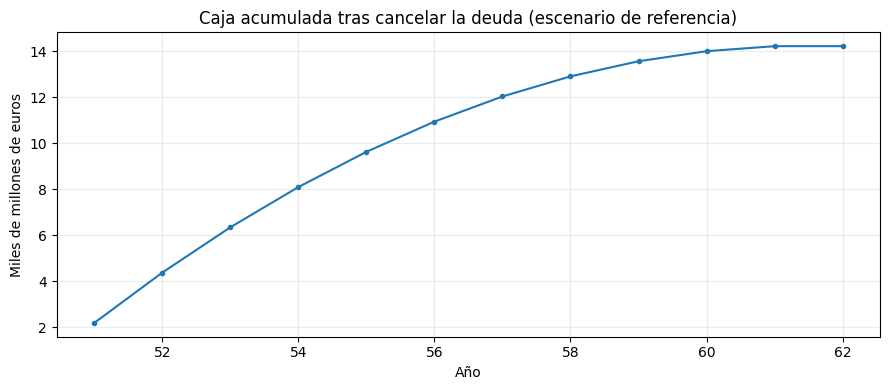

In [ ]:
# Plot cumulative cash after full debt repayment in the reference scenario
fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(post_ledger['Year'], post_ledger['Projected cash'] / 1e9,
        marker='o', markersize=3)  # Projected cash in billions of euros

ax.set(xlabel='Año', ylabel='Miles de millones de euros',
       title='Caja acumulada tras cancelar la deuda (escenario de referencia)')
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

## **Annual Financial Ledger: Years 1–62**

The annual financial ledger provides a **year-by-year overview of the programme's financial operations**, from the beginning of construction to the end of the 62-year evaluation period.

It brings together four main components:

1. **Programme revenues and expenditure:** housing sales, collected rent, net rental income and construction investment.
2. **Debt financing:** primary bond issuance, refinancing, coupon payments, principal repayments and outstanding debt.
3. **Public budget contributions:** annual transfers from the Spanish State Budget (PGE).
4. **Cash and restricted allocations:** unrestricted year-end cash balances and amounts earmarked for rental management and maintenance.

The ledger also reports cumulative financial flows, allowing readers to examine both the annual financing requirements and their evolution over the programme's lifetime.

### How to interpret the ledger

It is important to distinguish between **economic expenditure, financing transactions and accounting allocations**.

- **Debt issuance and refinancing** provide financing inflows, while principal repayments are financing outflows. They should not be confused with construction expenditure or interest costs.
- **Management and maintenance allocations** are provisions accumulated in a restricted fund. They are not observed expenditures, and actual withdrawals are not modelled.
- **Outstanding debt and cash balances** are financial stocks measured at a particular point in time. Unlike annual flows, they must not be summed across years.

Consequently, the combined measure of **planned costs and allocations** should not be interpreted as realised economic expenditure.

Tables present the financial amounts in euros, while the accompanying charts illustrate their evolution over the full 62-year period.

In [ ]:
# Build the annual financial ledger covering all 62 programme years
ledger = housing[['Year', 'Construction', 'Sales', 'Net rent']].copy()

# Add rental housing stock, gross receipts, and operating allocations
ledger['Rental homes'] = housing['Public rental homes']
ledger['Gross rent collected'] = housing['Gross rent'].to_numpy()
ledger['Management allocation'] = housing['Management allocation'].to_numpy()
ledger['Maintenance allocation'] = housing['Maintenance allocation'].to_numpy()
ledger['Total net receipts'] = ledger['Sales'] + ledger['Net rent']

# Merge housing operations with financing results from the reference scenario
finance_cols = ['Year', 'Primary issuance', 'Refinancing', 'Interest',
                'Principal paid', 'PGE', 'Cash', 'Debt', 'Residual maturity']
ledger = ledger.merge(reference_flows[finance_cols], how='left', on='Year')

# Set financing flows to zero after the repayment horizon
annual_flows = ['Primary issuance', 'Refinancing', 'Interest', 'Principal paid', 'PGE']
ledger[annual_flows] = ledger[annual_flows].fillna(0)

# Extend cash balances to year 62 using net rental receipts
last_cash = float(reference_flows['Cash'].iloc[-1])
ledger.loc[ledger['Year'] > reference_deadline, 'Cash'] = (
    last_cash + ledger.loc[ledger['Year'] > reference_deadline, 'Net rent'].cumsum())

ledger.loc[ledger['Year'] > reference_deadline, 'Debt'] = 0  # No outstanding debt after repayment
ledger['Cash'] = ledger['Cash'].fillna(0)
ledger['Debt'] = ledger['Debt'].fillna(0)

# Calculate the expected annual change in cash from all financial transactions
# Bond issuance and PGE increase cash, while construction, interest, and principal reduce it
ledger['Cash change'] = ledger['Total net receipts'] + ledger['Primary issuance'] + (
    ledger['Refinancing'] + ledger['PGE'] - ledger['Construction'] -
    ledger['Interest'] - ledger['Principal paid'])

ledger['Observed cash change'] = ledger['Cash'].diff().fillna(ledger['Cash'])  # Change in recorded cash balance

# Define cumulative indicators for income, expenditure, financing, and debt transactions
cumulative_cols = {
    'Sales': 'Cumulative sales',
    'Net rent': 'Cumulative net rent',
    'Total net receipts': 'Cumulative receipts',
    'Construction': 'Cumulative construction',
    'Management allocation': 'Cumulative management allocation',
    'Maintenance allocation': 'Cumulative maintenance allocation',
    'Interest': 'Cumulative interest',
    'PGE': 'Cumulative PGE',
    'Primary issuance': 'Cumulative primary issuance',
    'Refinancing': 'Cumulative refinancing',
    'Principal paid': 'Cumulative principal repaid'
}

# Calculate cumulative totals for each annual financial variable
for annual, cumulative in cumulative_cols.items():
    ledger[cumulative] = ledger[annual].cumsum()

# Track rental allocations separately from actual cash outlays
ledger['Restricted allocation'] = (ledger['Management allocation'] +
                                   ledger['Maintenance allocation'])
ledger['Restricted fund before withdrawals'] = ledger['Restricted allocation'].cumsum()
ledger['Cumulative rental allocations'] = ledger['Restricted fund before withdrawals']

# Distinguish observed expenditure from planned rental allocations
ledger['Cumulative observed outlays'] = (ledger['Cumulative construction'] +
                                         ledger['Cumulative interest'])
ledger['Cumulative planned costs and allocations'] = (ledger['Cumulative observed outlays'] +
                                                       ledger['Cumulative rental allocations'])

# Combine programme cash with restricted allocations before withdrawals
ledger['Total cash before restricted withdrawals'] = ledger['Cash'] + ledger['Restricted fund before withdrawals']

# Display selected years while keeping the complete 62-year ledger available for export
def show_ledger(columns, heading):
    print(heading)
    milestones = [1, 2, 3, 10, 11, 12, 20, 30, 40, 50, 60, 62]
    view = ledger.loc[ledger['Year'].isin(milestones), ['Year'] + columns].copy().set_index('Year')

    for column in columns:
        view[column] = view[column].map(euros)  # Format monetary amounts for display

    display(view)

# Show annual and cumulative housing income
show_ledger(['Sales', 'Gross rent collected', 'Management allocation',
             'Maintenance allocation', 'Net rent', 'Total net receipts',
             'Cumulative sales', 'Cumulative net rent', 'Cumulative receipts'],
            'Annual and cumulative programme income (euros):')

# Show construction expenditure, financing operations, and debt balances
show_ledger(['Construction', 'Interest', 'Primary issuance', 'Refinancing',
             'Principal paid', 'PGE', 'Debt', 'Cash', 'Restricted fund before withdrawals'],
            'Annual expenditure, public financing and debt position (euros):')

# Show cumulative programme costs and financing transactions
show_ledger(['Cumulative construction', 'Cumulative management allocation',
             'Cumulative maintenance allocation', 'Cumulative interest',
             'Cumulative planned costs and allocations',
             'Cumulative primary issuance', 'Cumulative refinancing',
             'Cumulative principal repaid', 'Cumulative PGE'],
            'Cumulative costs, debt transactions and PGE (euros):')

print('Restricted allocations are not actual paid costs. Refinancing is a funding flow.')

Annual and cumulative programme income (euros):


                 Sales Gross rent collected Management allocation  \
Year                                                                
1                  0 €                  0 €                   0 €   
2                  0 €                  0 €                   0 €   
3     12.000.000.000 €        273.600.000 €          41.040.000 €   
10    12.000.000.000 €      2.188.800.000 €         328.320.000 €   
11    12.000.000.000 €      2.462.400.000 €         369.360.000 €   
12    12.000.000.000 €      2.736.000.000 €         410.400.000 €   
20                 0 €      2.736.000.000 €         410.400.000 €   
30                 0 €      2.736.000.000 €         410.400.000 €   
40                 0 €      2.736.000.000 €         410.400.000 €   
50                 0 €      2.736.000.000 €         410.400.000 €   
60                 0 €        547.200.000 €          82.080.000 €   
62                 0 €                  0 €                   0 €   

     Maintenance allocation      

Annual expenditure, public financing and debt position (euros):


          Construction         Interest  Primary issuance      Refinancing  \
Year                                                                         
1      9.000.000.000 €              0 €  11.046.013.606 €              0 €   
2     18.000.000.000 €    413.275.795 €  17.459.289.401 €              0 €   
3     18.000.000.000 €  1.092.727.309 €   5.919.860.915 €              0 €   
10    18.000.000.000 €  2.802.961.168 €   6.097.934.773 €  1.739.849.832 €   
11     9.000.000.000 €  3.064.296.189 €   1.561.622.570 €  1.235.188.915 €   
12                 0 €  2.977.542.985 €               0 €              0 €   
20                 0 €  2.184.332.755 €               0 €  6.196.172.098 €   
30                 0 €  1.708.707.852 €               0 €  6.752.456.981 €   
40                 0 €  1.073.933.461 €               0 €    634.165.163 €   
50                 0 €    814.519.234 €               0 €              0 €   
60                 0 €              0 €               0 €       

Cumulative costs, debt transactions and PGE (euros):


     Cumulative construction Cumulative management allocation  \
Year                                                            
1            9.000.000.000 €                              0 €   
2           27.000.000.000 €                              0 €   
3           45.000.000.000 €                     41.040.000 €   
10         171.000.000.000 €                  1.477.440.000 €   
11         180.000.000.000 €                  1.846.800.000 €   
12         180.000.000.000 €                  2.257.200.000 €   
20         180.000.000.000 €                  5.540.400.000 €   
30         180.000.000.000 €                  9.644.400.000 €   
40         180.000.000.000 €                 13.748.400.000 €   
50         180.000.000.000 €                 17.852.400.000 €   
60         180.000.000.000 €                 20.478.960.000 €   
62         180.000.000.000 €                 20.520.000.000 €   

     Cumulative maintenance allocation Cumulative interest  \
Year                       

Restricted allocations are not actual paid costs. Refinancing is a funding flow.


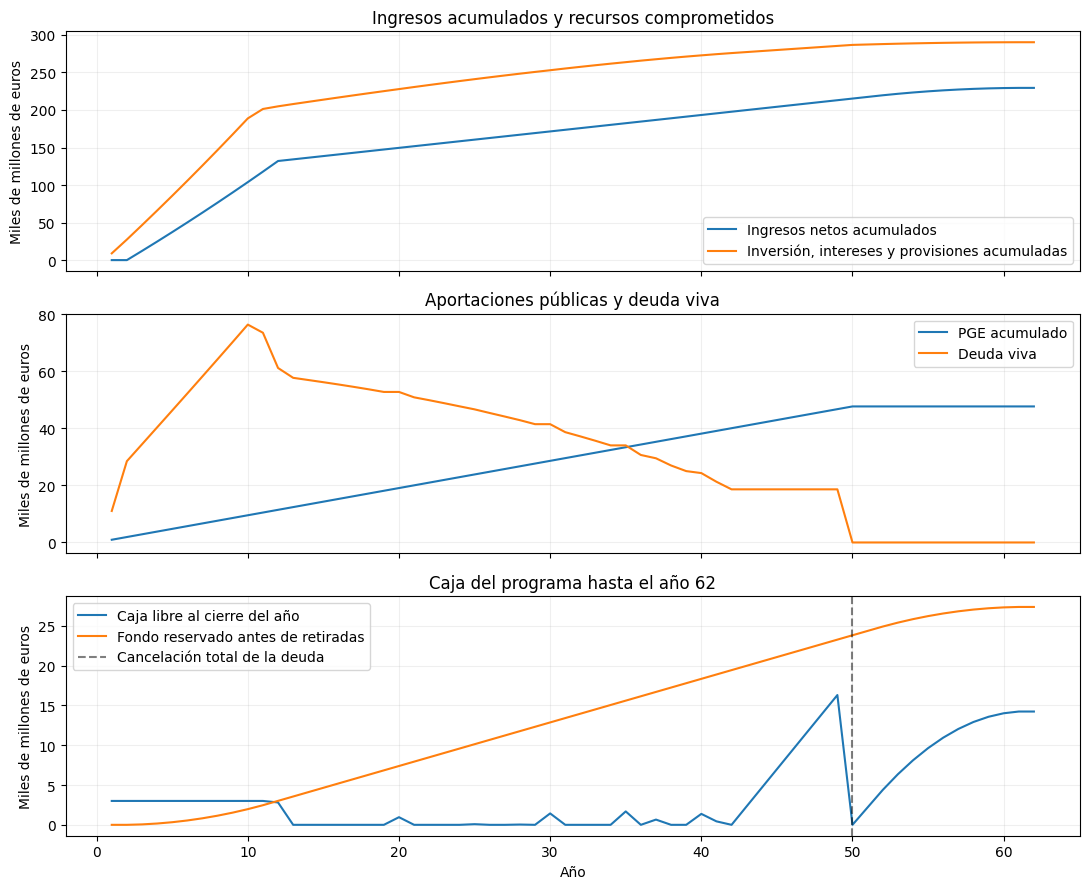

In [ ]:
# Plot the main financial indicators over the 62-year programme horizon
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)

# Compare cumulative net receipts with construction, interest, and rental allocations
axes[0].plot(ledger['Year'], ledger['Cumulative receipts'] / 1e9,
             label='Ingresos netos acumulados')
axes[0].plot(ledger['Year'], ledger['Cumulative planned costs and allocations'] / 1e9,
             label='Inversión, intereses y provisiones acumuladas')
axes[0].set(ylabel='Miles de millones de euros',
            title='Ingresos acumulados y recursos comprometidos')
axes[0].legend()


# Compare cumulative government contributions with outstanding debt
axes[1].plot(ledger['Year'], ledger['Cumulative PGE'] / 1e9,
             label='PGE acumulado')
axes[1].plot(ledger['Year'], ledger['Debt'] / 1e9,
             label='Deuda viva')
axes[1].set(ylabel='Miles de millones de euros',
            title='Aportaciones públicas y deuda viva')
axes[1].legend()


# Compare programme cash with restricted rental allocations
axes[2].plot(ledger['Year'], ledger['Cash'] / 1e9,
             label='Caja libre al cierre del año')
axes[2].plot(ledger['Year'], ledger['Restricted fund before withdrawals'] / 1e9,
             label='Fondo reservado antes de retiradas')

# Mark the reference debt repayment deadline
axes[2].axvline(reference_deadline, linestyle='--', color='black', alpha=0.5,
                label='Cancelación total de la deuda')

axes[2].set(xlabel='Año', ylabel='Miles de millones de euros',
            title='Caja del programa hasta el año 62')
axes[2].legend()

# Apply consistent grid formatting to all three charts
for ax in axes:
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

## **Validation and Limitations**

### 1. Model validation

The model includes a series of consistency checks designed to verify that the simulated financing strategies satisfy the specified accounting identities and financial constraints.

These checks cover:

- **Housing programme:** construction expenditure, housing deliveries and rental-income allocations
- **Cash-flow accounting:** consistency between revenues, expenditure, debt transactions, PGE contributions and cash balances
- **Debt management:** bond maturities, refinancing limits, prudential constraints and full repayment by the selected deadline
- **Liquidity:** compliance with minimum unrestricted cash requirements
- **Financial reporting:** consistency between the simulated debt portfolio and the reported maturity indicators

These checks establish **internal consistency under the model's assumptions**, not the practical feasibility of implementing the programme.

### 2. Main limitations

The analysis is subject to several important limitations.

**Housing and operating assumptions**

- Housing prices, rents and construction costs are fixed in nominal terms
- Each rental cohort generates a full year of income upon delivery
- Management and maintenance allocations are provisions; actual expenditures and withdrawals are not simulated
- Major rehabilitation, replacement investment and residual property values are excluded
- Rental income stops after 50 years per cohort, without assuming perpetual receipts

**Financial and fiscal assumptions**

- Interest rates remain constant by issuance tenor throughout each scenario
- The initial €3 billion liquidity requirement is illustrative
- The Treasury benchmark is a historical reference, not a legally binding debt-management rule
- Annual PGE requirements are determined endogenously, without an externally imposed budget ceiling in the baseline
- The model does not assess whether Spain has sufficient fiscal capacity to provide these contributions

**Broader economic considerations**

The analysis does not incorporate inflation, discounting, changing market conditions, housing-market capacity or wider macroeconomic effects. It also does not evaluate the administrative, legal or construction-sector feasibility of delivering the proposed housing programme.

### 3. Interpretation of the results

The findings are **conditional on the model's assumptions, constraints and the 30–62-year range of repayment horizons**.

For each horizon, the baseline optimisation prioritises minimising peak annual PGE contributions, followed by cumulative PGE and nominal interest. Therefore, the resulting financing strategy does not necessarily minimise interest independently of the budget objectives.

The separate interest–budget sensitivity analysis evaluates the potential reduction in interest costs under illustrative annual PGE ceilings, holding the 50-year repayment horizon fixed. It should not be interpreted as a complete fiscal or social cost-benefit comparison.

Finally, the operating projection ends in year 62. Under the model's cohort convention, **year 61 is the final year with rental receipts**, and no residual value is assigned to the housing stock at the end of the projection.

The results should therefore be interpreted as a **conditional financial assessment**, rather than evidence that the proposed programme is economically optimal or fiscally affordable.

In [ ]:
# Verify housing delivery targets and construction expenditure
assert housing['Homes delivered'].sum() == 1_000_000  # One million homes delivered
assert housing['Construction'].sum() == 180_000_000_000  # Total construction investment
assert housing.loc[housing['Year'] == 12, 'Public rental homes'].iloc[0] == 400_000  # Rental stock after delivery
assert housing.loc[housing['Year'] == 62, 'Public rental homes'].iloc[0] == 0  # End of the 50-year rental cohorts

# Verify rental income accounting and restricted allocations
assert (ledger['Gross rent collected'] - ledger['Management allocation'] -
        ledger['Maintenance allocation'] - ledger['Net rent']).abs().max() < 30_000

assert (ledger['Restricted fund before withdrawals'] -
        (ledger['Management allocation'] + ledger['Maintenance allocation']).cumsum()).abs().max() < 30_000

# Verify annual cash balances and the initial reserve requirement
assert (ledger['Cash change'] - ledger['Observed cash change']).abs().max() < 30_000
assert ledger.loc[ledger['Year'] <= 11, 'Cash'].min() >= cash_reserve - 30_000

# Verify full debt repayment and refinancing limits
assert abs(reference_flows['Debt'].iloc[-1]) < 30_000
assert (reference_flows['Refinancing'] <= reference_flows['Principal paid'] + 30_000).all()

# Verify total bond issuance equals total principal repayment
assert abs(reference_flows['Primary issuance'].sum() +
           reference_flows['Refinancing'].sum() - reference_flows['Principal paid'].sum()) < 30_000

# Reconcile reconstructed outstanding debt with the optimizer's debt balances
assert (treasury_comparison['Programme outstanding (€)'] -
        reference_flows['Debt']).abs().max() < 30_000

# Verify the minimum weighted average remaining maturity
assert (treasury_comparison.loc[treasury_comparison['Programme outstanding (€)'] > 1_000_000,
        'Programme WAM (years)'] >=
        treasury_comparison.loc[treasury_comparison['Programme outstanding (€)'] > 1_000_000,
        'Minimum required WAM (years)'] - 1e-5).all()

# Verify the maximum share of debt maturing within three years
assert (treasury_comparison.loc[treasury_comparison['Programme outstanding (€)'] > 1_000_000,
        'Programme due within 3 years (%)'] <=
        treasury_comparison.loc[treasury_comparison['Programme outstanding (€)'] > 1_000_000,
        'Maximum permitted 3-year share (%)'] + 0.001).all()

# Verify portfolio coverage and official Spanish Treasury benchmarks
assert len(portfolio_checks) > 300
assert abs(treasury_wam - 8.182075426559226) < 1e-7
assert abs(treasury_three_year_share - 0.28096146090807855) < 1e-7

# Verify that original-maturity debt shares sum to 100%
assert (bond_weights[maturities].sum(axis=1) - 100).abs().max() < 1e-8

# Verify that no debt or public financing remains after the reference repayment deadline
assert ledger.loc[ledger['Year'] > reference_deadline,
                  ['Debt','PGE','Interest','Principal paid','Refinancing','Primary issuance']].abs().max().max() < 30_000

print('All essential accounting and portfolio checks passed.')

All essential accounting and portfolio checks passed.


In [ ]:
# Save analysis outputs to the project folder in Google Drive when available
output_folder = Path.cwd() / 'results' if (Path.cwd() / 'data').is_dir() else Path.cwd().parent / 'results'  # Local repository results
colab_results = Path('/content/drive/MyDrive/Proyecto_Vivienda/04_Resultados')  # Google Drive results folder

# Use the Google Drive folder if it is mounted and accessible
if colab_results.is_dir():
    output_folder = colab_results

output_folder.mkdir(exist_ok=True, parents=True)  # Create the output directory if needed

# Define the 11 result tables to export
outputs = {
    'housing_repayment_horizons_v27.csv': comparison,
    'housing_interest_budget_frontier_v27.csv': interest_frontier,
    'housing_bond_issuance_reference_v27.csv': bond_issues,
    'housing_post_repayment_cash_v27.csv': post_table,
    'housing_annual_costs_reference_v27.csv': reference_costs,
    'housing_annual_receipts_v27.csv': receipts,
    'housing_refinancing_risk_v27.csv': refinancing_risk,
    'housing_annual_ledger_62_years_v27.csv': ledger,
    'housing_vs_treasury_residual_maturity_v27.csv': treasury_comparison,
    'housing_restricted_rental_fund_v27.csv': ledger[
        ['Year', 'Gross rent collected', 'Management allocation',
         'Maintenance allocation', 'Restricted fund before withdrawals',
         'Net rent', 'Cash', 'Total cash before restricted withdrawals']],
    'housing_outstanding_debt_tenor_weights_v27.csv': bond_weights,
}

# Export each DataFrame as a CSV without the pandas row index
for filename, table in outputs.items():
    table.to_csv(output_folder / filename, index=False)

print(f'Saved {len(outputs)} result tables in {output_folder}')

Saved 11 result tables in /content/drive/MyDrive/Proyecto_Vivienda/04_Resultados
